# Imports and Installs

In [1]:
!pip install yfinance

In [2]:
# read files shared via google-drive-link
# https://stackoverflow.com/questions/62759748/downloading-data-from-a-shared-google-drive-link-in-google-colab

!pip uninstall gdown -y && pip install gdown
!gdown -V

Found existing installation: gdown 6.4.2
Uninstalling gdown-6.4.2:
  Successfully uninstalled gdown-6.4.2
  Using cached gdown-6.4.2-py3-none-any.whl.metadata (11 kB)
Using cached gdown-6.4.2-py3-none-any.whl (50 kB)
gdown 6.4.2 at /usr/local/lib/python3.13/dist-packages


In [3]:
# IMPORTS
import numpy as np
import pandas as pd

#Fin Data Sources
import yfinance as yf
import pandas_datareader as pdr

#Data viz
import plotly.graph_objs as go
import plotly.graph_objects as go
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# measure time for ML HyperParams search
import time
from datetime import date

# ML models and utils
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

# Disable SettingWithCopyWarning
pd.options.mode.chained_assignment = None  # default='warn'

# 0) One DataFrame with Dummies


## 0.1) Read and truncate data (last 25 years from 2000), define variable sets


In [4]:
# https://stackoverflow.com/questions/62759748/downloading-data-from-a-shared-google-drive-link-in-google-colab
# precaculated data from Module 2: https://drive.google.com/file/d/1m3Qisfs2XfWk6Sw_Uk5kHLWqwQ0q8SKb/view?usp=sharing
!gdown https://drive.google.com/file/d/1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5/view?usp=sharing -O /content/


Using cookies from /root/.cache/gdown/cookies.txt
Downloading...
From (original): https://drive.google.com/uc?id=1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5
From (redirected): https://drive.google.com/uc?id=1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5&confirm=t&uuid=f03356c7-07fb-43c1-85a0-5f37c0753594
To: /content/stocks_df_combined_2026_09_18.parquet.brotli
100% 144M/144M [00:01<00:00, 86.5MB/s]


In [5]:
# full dataset for 33 stocks
df_full = pd.read_parquet("/content/stocks_df_combined_2026_09_18.parquet.brotli", )

In [6]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
Index: 240759 entries, 0 to 6018
Columns: 203 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(129), int32(64), int64(5), object(2)
memory usage: 315.9+ MB


In [7]:
# growth indicators (but not future growth)
GROWTH = [g for g in df_full.keys() if (g.find('growth_')==0)&(g.find('future')<0)]
GROWTH

['growth_1d',
 'growth_3d',
 'growth_7d',
 'growth_30d',
 'growth_90d',
 'growth_365d',
 'growth_dax_1d',
 'growth_dax_3d',
 'growth_dax_7d',
 'growth_dax_30d',
 'growth_dax_90d',
 'growth_dax_365d',
 'growth_snp500_1d',
 'growth_snp500_3d',
 'growth_snp500_7d',
 'growth_snp500_30d',
 'growth_snp500_90d',
 'growth_snp500_365d',
 'growth_dji_1d',
 'growth_dji_3d',
 'growth_dji_7d',
 'growth_dji_30d',
 'growth_dji_90d',
 'growth_dji_365d',
 'growth_epi_1d',
 'growth_epi_3d',
 'growth_epi_7d',
 'growth_epi_30d',
 'growth_epi_90d',
 'growth_epi_365d',
 'growth_gold_1d',
 'growth_gold_3d',
 'growth_gold_7d',
 'growth_gold_30d',
 'growth_gold_90d',
 'growth_gold_365d',
 'growth_wti_oil_1d',
 'growth_wti_oil_3d',
 'growth_wti_oil_7d',
 'growth_wti_oil_30d',
 'growth_wti_oil_90d',
 'growth_wti_oil_365d',
 'growth_brent_oil_1d',
 'growth_brent_oil_3d',
 'growth_brent_oil_7d',
 'growth_brent_oil_30d',
 'growth_brent_oil_90d',
 'growth_brent_oil_365d',
 'growth_btc_usd_1d',
 'growth_btc_usd_3d',


In [8]:
# leaving only Volume ==> generate ln(Volume)
OHLCV = ['Open','High','Low','Close','Close_x','Volume']

In [9]:
CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type']

In [10]:
# 2% median growth
df_full.growth_future_30d.describe()

,growth_future_30d
count,239769.000000
mean,1.026135
std,0.122007
min,0.246131
25%,0.960693
50%,1.021706
75%,1.085586
max,5.179688


In [11]:
# 59% of data records have positive future growth>0
df_full.is_positive_growth_30d_future.mean()

np.float64(0.5919612558616708)

In [12]:
# moving to strong growth (54% -> ~ 32%):
df_full.growth_future_30d.quantile(0.68)

np.float64(1.0651844068351353)

In [13]:
TO_PREDICT = [g for g in df_full.keys() if (g.find('future')>=0)]
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [14]:
# MAIN GOAL HERE IS TO MAKE SURE THAT 'OTHER' list is empty - we should categorize all feautures
# dropping some features - artifacts from joins, CATEGORICAL (to be converted to dummies), OHLCV
# 'index_x', 'index_y', 'index','Adj Close_y'
TO_DROP = ['Year','Date', 'Quarter', 'index_x', 'index_y', 'index', 'Close_y'] + CATEGORICAL + OHLCV
TO_DROP

['Year',
 'Date',
 'Quarter',
 'index_x',
 'index_y',
 'index',
 'Close_y',
 'Month',
 'Weekday',
 'Ticker',
 'ticker_type',
 'Open',
 'High',
 'Low',
 'Close',
 'Close_x',
 'Volume']

In [15]:
# let's define on more custom numerical features
# Add a small constant to avoid log(0)
df_full['ln_volume'] = df_full.Volume.apply(lambda x: np.log(x+ 1e-6))

In [16]:
# define additional columns (DUMMIES) on Dividends or Stock Splits
df_full['is_div_payout'] = (df_full.Dividends>0).astype(int)
df_full['is_stock_split'] = (df_full['Stock Splits']>0).astype(int)

In [17]:
# manually defined features
# 'Dividends' and 'Stock Splits' - absolute values of Divs and Splits.
# is_stock_split, is_div_payout - dummies on the dates when Divs and Splits are >0
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative','volatility', 'ln_volume', 'is_div_payout', 'is_stock_split', 'Dividends', 'Stock Splits']

In [18]:
# All Supported Ta-lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

In [19]:
TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl')>=0]
print(f'Technical patterns count = {len(TECHNICAL_PATTERNS)}, examples = {TECHNICAL_PATTERNS[0:5]}')

Technical patterns count = 61, examples = ['cdl2crows', 'cdl3blackrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside']


In [20]:
MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']

In [21]:
NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

In [22]:
# CHECK: NO OTHER INDICATORS LEFT
OTHER = [k for k in df_full.keys() if k not in OHLCV + CATEGORICAL + NUMERICAL + TO_DROP + TO_PREDICT]
OTHER

[]

In [23]:
df_full.Ticker.nunique()

33

In [24]:
# Non truncated stats
# tickers, min-max date, count of daily observations
df_full.groupby(['Ticker'])['Date'].agg(['min','max','count'])

,min,max,count
Ticker,,,
AAPL,1980-12-12,2026-09-18,11534
ACN,2001-07-19,2026-09-18,6329
AMZN,1997-05-15,2026-09-18,7382
ASML,1995-03-15,2026-09-18,7931
AVGO,2009-08-06,2026-09-18,4306
BHARTIARTL.NS,2002-07-01,2026-09-18,6016
BRK-B,1996-05-09,2026-09-18,7639
CDI.PA,1992-01-27,2026-09-18,8933
GOOG,2004-08-19,2026-09-18,5556


In [25]:
# truncated df_full with 25 years of data (and defined growth variables)
df = df_full[df_full.Date>='2000-01-01']
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 206 entries, Open to is_stock_split
dtypes: datetime64[ns](3), float64(130), int32(64), int64(7), object(2)
memory usage: 270.1+ MB


In [26]:
# Truncated info by ticker
df.groupby(['Ticker'])['Date'].agg(['min','max','count'])

,min,max,count
Ticker,,,
AAPL,2000-01-03,2026-09-18,6718
ACN,2001-07-19,2026-09-18,6329
AMZN,2000-01-03,2026-09-18,6718
ASML,2000-01-03,2026-09-18,6718
AVGO,2009-08-06,2026-09-18,4306
BHARTIARTL.NS,2002-07-01,2026-09-18,6016
BRK-B,2000-01-03,2026-09-18,6718
CDI.PA,2000-01-03,2026-09-18,6863
GOOG,2004-08-19,2026-09-18,5556


## 0.2) Dummies

In [27]:
# dummy variables can't be generated from Date and numeric variables ==> convert to STRING (to define groups for Dummies)
df.loc[:,'Month'] = df.Month.dt.strftime('%B')
df.loc[:,'Weekday'] = df.Weekday.astype(str)

/tmp/ipykernel_33555/2164722115.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['January' 'January' 'January' ... 'September' 'September' 'September']' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  df.loc[:,'Month'] = df.Month.dt.strftime('%B')
/tmp/ipykernel_33555/2164722115.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['0' '1' '2' ... '2' '3' '4']' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.loc[:,'Weekday'] = df.Weekday.astype(str)


### 0.2.2) Generate all dummies

In [28]:
# what are the categorical features?
# SHOULD we remove Ticker from CATEGORICAL? To generalize it even more?
CATEGORICAL

['Month', 'Weekday', 'Ticker', 'ticker_type']

In [29]:
# Generate dummy variables (no need for bool, let's have int32 instead)
dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')

In [30]:
# the list of dummies
dummy_variables.keys()

Index(['Month_April', 'Month_August', 'Month_December', 'Month_February',
       'Month_January', 'Month_July', 'Month_June', 'Month_March', 'Month_May',
       'Month_November', 'Month_October', 'Month_September', 'Weekday_0',
       'Weekday_1', 'Weekday_2', 'Weekday_3', 'Weekday_4', 'Weekday_5',
       'Weekday_6', 'Ticker_AAPL', 'Ticker_ACN', 'Ticker_AMZN', 'Ticker_ASML',
       'Ticker_AVGO', 'Ticker_BHARTIARTL.NS', 'Ticker_BRK-B', 'Ticker_CDI.PA',
       'Ticker_GOOG', 'Ticker_HDB', 'Ticker_HINDUNILVR.NS', 'Ticker_IBN',
       'Ticker_IDEXY', 'Ticker_INFY', 'Ticker_ITC.NS', 'Ticker_JPM',
       'Ticker_LICI.NS', 'Ticker_LLY', 'Ticker_LT.NS', 'Ticker_MC.PA',
       'Ticker_META', 'Ticker_MSFT', 'Ticker_NVDA', 'Ticker_NVO',
       'Ticker_OR.PA', 'Ticker_RELIANCE.NS', 'Ticker_RMS.PA', 'Ticker_SAP',
       'Ticker_SBIN.NS', 'Ticker_SIE.DE', 'Ticker_TCS.NS', 'Ticker_TTE',
       'Ticker_V', 'ticker_type_EU', 'ticker_type_INDIA', 'ticker_type_US'],
      dtype='object')

In [31]:
# get dummies names in a list
DUMMIES = dummy_variables.keys().to_list()
DUMMIES

['Month_April',
 'Month_August',
 'Month_December',
 'Month_February',
 'Month_January',
 'Month_July',
 'Month_June',
 'Month_March',
 'Month_May',
 'Month_November',
 'Month_October',
 'Month_September',
 'Weekday_0',
 'Weekday_1',
 'Weekday_2',
 'Weekday_3',
 'Weekday_4',
 'Weekday_5',
 'Weekday_6',
 'Ticker_AAPL',
 'Ticker_ACN',
 'Ticker_AMZN',
 'Ticker_ASML',
 'Ticker_AVGO',
 'Ticker_BHARTIARTL.NS',
 'Ticker_BRK-B',
 'Ticker_CDI.PA',
 'Ticker_GOOG',
 'Ticker_HDB',
 'Ticker_HINDUNILVR.NS',
 'Ticker_IBN',
 'Ticker_IDEXY',
 'Ticker_INFY',
 'Ticker_ITC.NS',
 'Ticker_JPM',
 'Ticker_LICI.NS',
 'Ticker_LLY',
 'Ticker_LT.NS',
 'Ticker_MC.PA',
 'Ticker_META',
 'Ticker_MSFT',
 'Ticker_NVDA',
 'Ticker_NVO',
 'Ticker_OR.PA',
 'Ticker_RELIANCE.NS',
 'Ticker_RMS.PA',
 'Ticker_SAP',
 'Ticker_SBIN.NS',
 'Ticker_SIE.DE',
 'Ticker_TCS.NS',
 'Ticker_TTE',
 'Ticker_V',
 'ticker_type_EU',
 'ticker_type_INDIA',
 'ticker_type_US']

In [32]:
len(DUMMIES)

55

In [33]:
# Concatenate the dummy variables with the original DataFrame
df_with_dummies = pd.concat([df, dummy_variables], axis=1)

In [34]:
df_with_dummies[NUMERICAL+DUMMIES].info()

<class 'pandas.core.frame.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 243 entries, growth_1d to ticker_type_US
dtypes: float64(123), int32(117), int64(3)
memory usage: 286.3 MB


### 0.2.4) Temporal split

In [35]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    """
    Splits a DataFrame into three buckets based on the temporal order of the 'Date' column.

    Args:
        df (DataFrame): The DataFrame to split.
        min_date (str or Timestamp): Minimum date in the DataFrame.
        max_date (str or Timestamp): Maximum date in the DataFrame.
        train_prop (float): Proportion of data for training set (default: 0.7).
        val_prop (float): Proportion of data for validation set (default: 0.15).
        test_prop (float): Proportion of data for test set (default: 0.15).

    Returns:
        DataFrame: The input DataFrame with a new column 'split' indicating the split for each row.
    """
    # Define the date intervals
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)

    # Assign split labels based on date ranges
    split_labels = []
    for date in df['Date']:
        if date <= train_end:
            split_labels.append('train')
        elif date <= val_end:
            split_labels.append('validation')
        else:
            split_labels.append('test')

    # Add 'split' column to the DataFrame
    df['split'] = split_labels

    return df

In [36]:
min_date_df = df_with_dummies.Date.min()
max_date_df = df_with_dummies.Date.max()

df_with_dummies = temporal_split(df_with_dummies,
                                 min_date = min_date_df,
                                 max_date = max_date_df)

In [37]:
# the split is approximate!
  # as tickers can have a different history
df_with_dummies['split'].value_counts()/len(df_with_dummies)

,count
split,
train,0.676458
test,0.163936
validation,0.159606


In [38]:
# remove the "segmentation" problem (warning message on df performance after many joins and data transformations)
new_df = df_with_dummies.copy()

In [39]:
# EXACT DATES for the split:
# time split on train/validation/test: FIXED dates of split, approx. 70%, 15%, 15% split
new_df.groupby(['split'])['Date'].agg({'min','max','count'})

,count,min,max
split,,,
test,33163,2022-09-16,2026-09-18
train,136842,2000-01-03,2018-09-13
validation,32287,2018-09-14,2022-09-15


In [40]:
# Full dataframe (transformed and truncated to 25 years)
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 202292 entries, 3490 to 6018
Columns: 262 entries, Open to split
dtypes: datetime64[ns](2), float64(130), int32(118), int64(7), object(5)
memory usage: 314.8+ MB


In [41]:
# check one record: it has abs. values, text, and numbers
new_df.head(1)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,split
3490,35.623602,36.00298,33.992277,35.377007,53228400.0,0.0,0.0,MSFT,2000,January,...,0,0,0,0,0,0,0,0,1,train


In [42]:
# what do we try to predict
new_df[TO_PREDICT].head(1)

,growth_future_30d,is_positive_growth_30d_future
3490,0.845576,0


### 0.2.5 Define dataframes for Modeling (ML) and clean them

In [43]:
# Features to be used in predictions (incl. new dummies)
features_list = NUMERICAL+DUMMIES


# What we're trying to predict?
to_predict = 'is_positive_growth_30d_future'

train_df = new_df[new_df.split.isin(['train'])].copy(deep=True)
valid_df = new_df[new_df.split.isin(['validation'])].copy(deep=True)
train_valid_df = new_df[new_df.split.isin(['train','validation'])].copy(deep=True)
test_df =  new_df[new_df.split.isin(['test'])].copy(deep=True)

# ONLY numerical Separate features and target variable for training and testing sets
X_train = train_df[features_list+[to_predict]]
X_valid = valid_df[features_list+[to_predict]]
X_train_valid = train_valid_df[features_list+[to_predict]]
X_test = test_df[features_list+[to_predict]]

# this to be used for predictions and join to the original dataframe new_df
X_all =  new_df[features_list+[to_predict]].copy(deep=True)

print(f'length: X_train {X_train.shape},  X_validation {X_valid.shape}, X_test {X_test.shape}, X_train_valid = {X_train_valid.shape},  all combined: X_all {X_all.shape}')

length: X_train (136842, 244),  X_validation (32287, 244), X_test (33163, 244), X_train_valid = (169129, 244),  all combined: X_all (202292, 244)


In [44]:
# Prepare a dataframe for ML:
  # +-inf to NaN, all NaNs to 0s
def clean_dataframe_from_inf_and_nan(df:pd.DataFrame):
  df.replace([np.inf, -np.inf], np.nan, inplace=True)
  df.fillna(0, inplace=True)
  return df

In [45]:
# Clean from +-inf and NaNs:

X_train = clean_dataframe_from_inf_and_nan(X_train)
X_valid = clean_dataframe_from_inf_and_nan(X_valid)
X_train_valid = clean_dataframe_from_inf_and_nan(X_train_valid)
X_test = clean_dataframe_from_inf_and_nan(X_test)
X_all = clean_dataframe_from_inf_and_nan(X_all)

In [46]:
y_train = X_train[to_predict]
y_valid = X_valid[to_predict]
y_train_valid = X_train_valid[to_predict]
y_test = X_test[to_predict]
y_all =  X_all[to_predict]

# remove y_* from X_* dataframes
del X_train[to_predict]
del X_valid[to_predict]
del X_train_valid[to_predict]
del X_test[to_predict]
del X_all[to_predict]

# 1) Modeling

## 1.1) Manual 'rule of thumb' predictions

* (pred0) CCI>200 (binary, on technical indicator CCI)
* (pred1) growth_30d>1
* (pred2) (growth_30d>1) & (growth_snp500_30d>1)
* (pred3) (DGS10 <= 4) & (DGS5 <= 1)
* (pred4) (DGS10 > 4) & (FEDFUNDS <= 4.795)

In [47]:
# generate manual predictions
# Let's label all prediction features with prefix "pred"
new_df['pred0_manual_cci'] = (new_df.cci>200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d>1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)

# new manual predictions from HA
new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)

In [48]:
# example output manual predictions:
new_df[['cci','growth_30d','growth_snp500_30d','pred0_manual_cci','pred1_manual_prev_g1','pred2_manual_prev_g1_and_snp','pred3_manual_dgs10_5','pred4_manual_dgs10_fedfunds','is_positive_growth_30d_future']].sample(10)

,cci,growth_30d,growth_snp500_30d,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_positive_growth_30d_future
3631,-17.070333,0.928825,0.975403,0,0,0,1,0,1
5279,-87.422357,0.964977,0.942583,0,0,0,1,0,0
1919,-140.843162,0.913645,1.094511,0,0,0,1,0,1
7104,-43.290931,1.226278,1.042221,0,1,1,0,0,0
4426,5.703177,0.936056,1.022007,0,0,0,1,0,1
1557,-160.313101,1.216199,1.090385,0,1,1,0,1,0
7255,-129.061391,0.860590,1.028838,0,0,0,0,1,0
2630,-100.748027,0.941933,NaN,0,0,0,0,1,1
2169,-86.677448,1.062516,1.025671,0,1,1,1,0,0
5521,157.982720,1.094429,0.999180,0,1,0,1,0,1


In [49]:
# List of current predictions
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds']

In [50]:
# Function to find all predictions (starting from 'pred'), generate is_correct (correctness of each prediction)
# and precision on TEST dataset (assuming there is df["split"] column with values 'train','validation','test'

# returns 2 lists of features: PREDICTIONS and IS_CORRECT

def get_predictions_correctness(df:pd.DataFrame, to_predict:str):
  PREDICTIONS = [k for k in df.keys() if k.startswith('pred')]
  print(f'Prediction columns founded: {PREDICTIONS}')

  # add columns is_correct_
  for pred in PREDICTIONS:
    part1 = pred.split('_')[0] # first prefix before '_'
    df[f'is_correct_{part1}'] =  (new_df[pred] == new_df[to_predict]).astype(int)

  # IS_CORRECT features set
  IS_CORRECT =  [k for k in df.keys() if k.startswith('is_correct_')]
  print(f'Created columns is_correct: {IS_CORRECT}')

  print('Precision on TEST set for each prediction:')
  # define "Precision" for ALL predictions on a Test dataset (~4 last years of trading)
  for i,column in enumerate(IS_CORRECT):
    prediction_column = PREDICTIONS[i]
    is_correct_column = column
    filter = (new_df.split=='test') & (new_df[prediction_column]==1)
    print(f'Prediction column:{prediction_column} , is_correct_column: {is_correct_column}')
    print(new_df[filter][is_correct_column].value_counts())
    print(new_df[filter][is_correct_column].value_counts()/len(new_df[filter]))
    print('---------')

  return PREDICTIONS, IS_CORRECT

In [51]:
# check the precision of currect predictions. to_predict = previously defined variable to predict
PREDICTIONS, IS_CORRECT = get_predictions_correctness(df = new_df, to_predict= to_predict)

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    520
0    401
Name: count, dtype: int64
is_correct_pred0
1    0.564604
0    0.435396
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    11086
0     8072
Name: count, dtype: int64
is_correct_pred1
1    0.578662
0    0.421338
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
1    8728
0    6516
Name: count, dtype: int64
is_correct_pred2
1    0.572553
0    0.427447
Name: count, dtype: float64
-----

In [52]:
# SAMPLE: check predictions vs. is_correct vs. is_positive_growth variable
new_df[PREDICTIONS+IS_CORRECT+[to_predict]].sample(10)

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4,is_positive_growth_30d_future
6044,0,1,1,1,0,0,1,1,1,0,1
4869,0,1,1,0,0,1,0,0,1,1,0
1241,0,1,1,1,0,0,1,1,1,0,1
8423,0,1,1,1,0,1,0,0,0,1,0
3254,0,1,1,1,1,0,1,1,1,1,1
1805,0,0,0,1,1,0,0,0,1,1,1
10734,0,1,1,0,0,0,1,1,0,0,1
5611,0,1,0,1,0,1,0,1,0,1,0
3234,0,0,0,1,0,1,1,1,0,1,0
1225,0,1,1,1,0,1,0,0,0,1,0


## 1.2) Decision Tree Classifier

### 1.2.1) Defining Functions to clean_df(), fit_decision_tree(), predict_decision_tree()
* here we discuss only the Decision Tree Classifier for binary predictions (and not the Regressor)

In [53]:
# Estimation/fit function (using dataframe of features X and what to predict y) --> optimising total accuracy
# max_depth is hyperParameter
def fit_decision_tree(X, y, max_depth=20):
# Initialize the Decision Tree Classifier
  clf = DecisionTreeClassifier(max_depth=max_depth,
                               random_state=42)

  # Fit the classifier to the training data
  clf.fit(X, y)
  return clf, X.columns

In [54]:
%%time
clf_10, train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=10)

CPU times: user 30.6 s, sys: 141 ms, total: 30.7 s
Wall time: 30.9 s


In [55]:
# predict on a full dataset
y_pred_all = clf_10.predict(X_all)

In [56]:
# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred5_clf_10'] = y_pred_all

In [57]:
# new prediction is added --> need to recalculate the correctness
PREDICTIONS, IS_CORRECT = get_predictions_correctness(df = new_df, to_predict = to_predict)

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    520
0    401
Name: count, dtype: int64
is_correct_pred0
1    0.564604
0    0.435396
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    11086
0     8072
Name: count, dtype: int64
is_correct_pred1
1    0.578662
0    0.421338
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
1    8728
0    6516
Name: count, dtype: int64
is_correct_pred2
1    0.572553
0    0.4274

## 1.2.3 Hyperparams tuning for a Decision Tree Classifier

In [58]:
# visualisation: decision tree for a few levels (max_depth variable)
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# https://stackoverflow.com/questions/20156951/how-do-i-find-which-attributes-my-tree-splits-on-when-using-scikit-learn
from sklearn.tree import export_text

In [59]:
# (8min runtime) UNCOMMENT TO RUN IT AGAIN
# %%time
# # hyper params tuning for a Decision Tree

# precision_by_depth = {}
# best_precision = 0
# best_depth = 0

# for depth in range(1,21):
#   print(f'Working with a tree of a max depth= {depth}')
#   # fitting the tree on X_train, y_train
#   clf,train_columns = fit_decision_tree(X=X_train_valid,
#                            y=y_train_valid,
#                            max_depth=depth) #applying custom hyperparam
#   # getting the predictions for TEST and accuracy score
#   y_pred_valid = clf.predict(X_valid)
#   precision_valid = precision_score(y_valid, y_pred_valid)
#   y_pred_test = clf.predict(X_test)
#   precision_test = precision_score(y_test, y_pred_test)
#   print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')
#   # saving to the dict
#   precision_by_depth[depth] = round(precision_test,4)
#   # updating the best precision
#   if precision_test >= best_precision:
#     best_precision = round(precision_test,4)
#     best_depth = depth
#   # plot tree - long
#   # plt.figure(figsize=(20,10))  # Set the size of the figure
#   # plot_tree(clf,
#   #           filled=True,
#   #           feature_names=train_columns,
#   #           class_names=['Negative', 'Positive'],
#   #           max_depth=2)
#   # plt.show()
#   # plot tree - short
#   tree_rules = export_text(clf, feature_names=list(X_train), max_depth=3)
#   print(tree_rules)
#   print('------------------------------')

# print(f'All precisions by depth: {precision_by_depth}')
# print(f'The best precision is {best_precision} and the best depth is {best_depth} ')

In [60]:
# Results of Hyper parameters tuning for a Decision Tree
# print(precision_by_depth)

In [61]:
# pre-calculated results of Hyperparameter tuning: full dataset (300 features) and is_positive_growth_5d
precision_by_depth = {1: 0.5701, 2: 0.6225, 3: 0.572, 4: 0.6292, 5: 0.6133, 6: 0.6088, 7: 0.6263, 8: 0.613, 9: 0.6062, 10: 0.5962, 11: 0.6139, 12: 0.5818, 13: 0.5864, 14: 0.5851, 15: 0.5808, 16: 0.5736, 17: 0.5791, 18: 0.5832, 19: 0.5772, 20: 0.5968}


In [62]:
# Convert the dictionary to a DataFrame
df = pd.DataFrame(list(precision_by_depth.items()), columns=['max_depth', 'precision_score'])
df.loc[:,'precision_score'] = df.precision_score*100.0 # need for % visualisation

# Create the bar chart using Plotly Express
fig = px.bar(df,
             x='max_depth',
             y='precision_score',
            #  title='Precision Score vs. Max Depth for a Decision Tree',
             labels={'max_depth': 'Max Depth', 'precision_score': 'Precision Score'},
             range_y=[54, 65],
             text='precision_score')

# Update the text format to display as percentages
fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')

# Center the title
fig.update_layout(title={'text': 'Precision Score vs. Max Depth for a Decision Tree', 'x': 0.5, 'xanchor': 'center'})


# Show the figure
fig.show()

In [63]:
# 2026: top model (a little bit too simplistic)
%%time
clf_4, train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=4)


# predict on a full dataset
y_pred_all = clf_4.predict(X_all)


# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred6_clf_4'] = y_pred_all

CPU times: user 13.8 s, sys: 333 ms, total: 14.2 s
Wall time: 14.3 s


In [64]:
# MANUAL SECOND BEST, need some complexity for the threshhold rules
# found earlier in HyperParams Tuning
best_depth = 7
best_precision = precision_by_depth[best_depth]

In [65]:
%%time
clf_best,train_columns = fit_decision_tree(X=X_train_valid,
                           y=y_train_valid,
                           max_depth=best_depth)

CPU times: user 23.2 s, sys: 99.2 ms, total: 23.3 s
Wall time: 24.2 s


In [66]:
# For a DecisionTreeClassifier in scikit-learn, the concept of trainable parameters differs from that of neural networks.
# In decision trees, the parameters are the structure of the tree itself (nodes and splits) rather than weights.
# However, you can still get a sense of the model's complexity by looking at the number of nodes and leaves.

# Here's how you can get this information for your trained DecisionTreeClassifier (referred to as clf_best):

# Get the number of nodes and leaves in the tree
n_nodes = clf_best.tree_.node_count
n_leaves = clf_best.get_n_leaves()

print(f"Number of nodes: {n_nodes}")
print(f"Number of leaves: {n_leaves}")

Number of nodes: 243
Number of leaves: 122


In [67]:
clf_best

DecisionTreeClassifier(max_depth=7, random_state=42)

In [68]:
# predict on a full dataset
y_pred_clf_best = clf_best.predict(X_all)

In [69]:
# defining a new prediction vector is easy now, as the dimensions will match
new_df['pred7_clf_second_best'] = y_pred_clf_best

In [70]:
# new prediction is added --> need to recalculate the correctness
PREDICTIONS, IS_CORRECT = get_predictions_correctness(df = new_df, to_predict = to_predict)

Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10', 'pred6_clf_4', 'pred7_clf_second_best']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5', 'is_correct_pred6', 'is_correct_pred7']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    520
0    401
Name: count, dtype: int64
is_correct_pred0
1    0.564604
0    0.435396
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    11086
0     8072
Name: count, dtype: int64
is_correct_pred1
1    0.578662
0    0.421338
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
is_correct_pred2
1    872

## 1.3) Random Forest
https://scikit-learn.org/stable/modules/ensemble.html#random-forests-and-other-randomized-tree-ensembles

In [71]:
from sklearn.ensemble import RandomForestClassifier
import time

In [72]:
# (15 min runtime FOR v28 or v5e-1 machine) UNCOMMENT BELOW TO RUN HYPERPARAMs optimisation again
# # hyper params tuning

# %%time

# precision_matrix = {}
# best_precision = 0
# best_depth = 0
# best_estimators = 1

# for depth in [4, 5, 7, 9, 11, 13, 15]:
#   for estimators in [10,20,50,100]:
#     print(f'Working with HyperParams: depth = {depth}, estimators = {estimators}')

#     # Start timing
#     start_time = time.time()
#     # fitting the tree on X_train, y_train
#     rf = RandomForestClassifier(n_estimators = estimators,
#                                 max_depth = depth,
#                                 random_state = 42,
#                                 n_jobs = -1)

#     rf = rf.fit(X_train_valid, y_train_valid)

#     # getting the predictions for TEST and accuracy score
#     y_pred_valid = rf.predict(X_valid)
#     precision_valid = precision_score(y_valid, y_pred_valid)
#     y_pred_test = rf.predict(X_test)
#     precision_test = precision_score(y_test, y_pred_test)
#     print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')

#     # saving to the dict
#     precision_matrix[depth, estimators] = round(precision_test,4)

#     # Measure elapsed time
#     elapsed_time = time.time() - start_time
#     print(f'Time for training: {elapsed_time:.2f} seconds, or {elapsed_time/60:.2f} minutes')

#     # updating the best precision
#     if precision_test >= best_precision:
#       best_precision = round(precision_test,4)
#       best_depth = depth
#       best_estimators = estimators
#       print(f'New best precision found for depth={depth}, estimators = {estimators}')

#     print('------------------------------')

# print(f'Matrix of precisions: {precision_matrix}')
# print(f'The best precision is {best_precision} and the best depth is {best_depth} ')

In [73]:
# uncomment when you run the hyperparam tuning again
# print(precision_matrix)

In [74]:
# pre-calculated best precision matrix (max_depth, n_estimators) for Random Forest
best_precision_matrix_random_forest = {(4, 10): 0.5718, (4, 20): 0.5711, (4, 50): 0.5701, (4, 100): 0.57, (5, 10): 0.5571, (5, 20): 0.5495, (5, 50): 0.5531, (5, 100): 0.5553, (7, 10): 0.5668, (7, 20): 0.592, (7, 50): 0.5804, (7, 100): 0.5737, (9, 10): 0.578, (9, 20): 0.5706, (9, 50): 0.5644, (9, 100): 0.568, (11, 10): 0.5676, (11, 20): 0.5872, (11, 50): 0.5868, (11, 100): 0.5879, (13, 10): 0.5642, (13, 20): 0.5781, (13, 50): 0.5988, (13, 100): 0.6031, (15, 10): 0.5634, (15, 20): 0.5903, (15, 50): 0.5839, (15, 100): 0.6012}


In [75]:

# Convert data to DataFrame
df = pd.DataFrame.from_dict(best_precision_matrix_random_forest, orient='index', columns=['precision_score']).reset_index()

# Rename the columns for clarity
df.columns = ['max_depth_and_metric', 'precision_score']

# Separate the tuple into two columns
df[['max_depth', 'n_estimators']] = pd.DataFrame(df['max_depth_and_metric'].tolist(), index=df.index)

# Drop the combined column
df = df.drop(columns=['max_depth_and_metric'])

# Create line plot using Plotly Express
fig = px.line(df, x='max_depth', y='precision_score', color='n_estimators',
              labels={'max_depth': 'Max Depth', 'precision_score': 'Precision Score', 'n_estimators': 'Number of Estimators'},
              title='Random Forest Models: Precision Score vs. Max Depth for Different Number of Estimators')

# Adjust x-axis range
fig.update_xaxes(range=[5, 20])

# Show the figure
fig.show()

In [76]:
# MANUALLY SELECTED BEST - should have enough complexity and smoothness (n_estimators)
rf_best_n_estimators = 100
# MANUALLY SELECTED BEST - should have enough complexity
rf_best_max_depth = 13

In [77]:
%%time

#
# several minutes to compute (2 min)

rf_best = RandomForestClassifier(n_estimators = rf_best_n_estimators,
                                 max_depth = rf_best_max_depth,
                                 random_state = 42,
                                 n_jobs = -1)

rf_best = rf_best.fit(X_train_valid, y_train_valid)

CPU times: user 3min 37s, sys: 473 ms, total: 3min 38s
Wall time: 2min 8s


## 1.4 Logistic Regression

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

There can be many reasons when Logistic Regression does not converge: https://forecastegy.com/posts/how-to-solve-logistic-regression-not-converging-in-scikit-learn/

In [78]:
from sklearn.linear_model import LogisticRegression

In [79]:
# Large feature magnitudes can cause convergence issues. If you haven’t already, scale your data:
# (only for the Logistic regression, and maybe for the Neural Network)
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()
# X_train_valid_scaled = scaler.fit_transform(X_train_valid)
# X_valid_scaled = scaler.transform(X_valid)
# X_test_scaled = scaler.transform(X_test)

# precision_matrix = {}
# best_precision = 0
# best_C = 0
# best_iter = 0

# for c in [1, 0.1, 0.01]:
#   for iter in [50, 100, 200]:
#     print(f'Working with HyperParams: C = {c} (positive float, smaller = stronger regularization), max_iter={iter}')
#     # fitting the tree on X_train, y_train
#       # hyperParam C should be between 0 and 1
#     lr = LogisticRegression(C=c,
#                             random_state=42,
#                             max_iter=iter,
#                             solver='sag',
#                             n_jobs=-1)

#     lr = lr.fit(X_train_valid_scaled, y_train_valid)

#     # getting the predictions for TEST and accuracy score
#     y_pred_valid = lr.predict(X_valid_scaled)
#     precision_valid = precision_score(y_valid, y_pred_valid)
#     y_pred_test = lr.predict(X_test_scaled)
#     precision_test = precision_score(y_test, y_pred_test)
#     print(f'  Precision on test is {precision_test}, (precision on valid is {precision_valid} - tend to overfit)')
#     # saving to the dict
#     precision_matrix[(c,iter)] = round(precision_test,4)
#     # updating the best precision
#     if precision_test >= best_precision:
#       best_precision = round(precision_test,4)
#       best_C = c
#       best_iter = iter
#       print(f'New best precision found for C={c}')
#       print('------------------------------')

# print(f'Matrix of precisions: {precision_matrix}')
# print(f'The best precision is {best_precision} and the best C is {best_C}, best max_iter = {best_iter}  ')

In [80]:
# UNCOMMENT TO SEE THE RESULTS OF THE RUN
# print(precision_matrix)

In [81]:
# Params on C, iter
best_precision_matrix_logistic_regression = {(1, 50): 0.5553, (1, 100): 0.5559, (1, 200): 0.5444, (0.1, 50): 0.5548, (0.1, 100): 0.5548, (0.1, 200): 0.5478, (0.01, 50): 0.5496, (0.01, 100): 0.5516, (0.01, 200): 0.5509}

In [82]:
list(best_precision_matrix_logistic_regression.items())[0]

((1, 50), 0.5553)

In [83]:
# Visualise precision scores

# Prepare the data
rows = []
for key, value in list(best_precision_matrix_logistic_regression.items()):
    C, max_iter = key
    combination_label = f'C={C}, max_iter={max_iter}'
    rows.append({'Combination': combination_label, 'Precision': value})

df = pd.DataFrame(rows)
df.loc[:,'Precision'] = df.Precision*100.0 # need for % visualisation

# Create the bar chart
fig = px.bar(df,
             x='Combination',
             y='Precision',
             text='Precision'
             )

# Customize the layout for better readability
fig.update_layout(
    xaxis_title='Hyperparams combinations of <C, Max Iterations>',
    yaxis_title='Precision Score',
    xaxis_tickangle=-45,
    title={
        'text': 'Precision Scores for Various Logistic Regression Hyperparameter Combinations',
        'y':0.95,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    }
)


# Update the text position
fig.update_traces(texttemplate='%{text:.2f}%',
                  textposition='inside',
                  textfont_color='white')

# Show the figure
fig.show()

## 1.5) ADVANCED: Deep Neural Network (DNN) and hyperparams tuning
* Tutorial from Tensorflow.org
* TowardsDataScience Hyperparameter Optimization with Keras
* Machine Learning Mastery tutorial with Keras Deep Learning

In [84]:
# https://towardsdatascience.com/hyperparameter-optimization-with-keras-b82e6364ca53


# Extended params set

# p = {'lr': [0.01, 0.03,0.1, 0.3,1,3,10],
#      'first_neuron': [0,16,32,64,128,256],
#      'second_neuron':[0,16,32,64,128,256],
#      'first_dropout':[0,0.2,0.3],
#      'second_dropout':[0,0.2,0.3],
#      'activation_first':['relu','sigmoid','linear'],
#      'activation_second':['relu','sigmoid','linear'],
#     #  'activation_first':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
#     #  'activation_second':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
#     #  'batch_size':(2,30,10),
#     #  'loss': ('mse','mae'),
#     #  'epochs':[150],
#     #  'shape': ['brick','long_funnel'],
#      'optimizer':['adam', 'nadam', 'rmaprop','sgd'],
#     #  'losses': [logcosh, binary_crossentropy],
#     #  'last_activation':[sigmoid]
#      }


# Reduced params set and available options
p = {'lr': [0.1],
     'first_neuron': [12,24,32,48,96, 128, 196, 256],
     'second_neuron':[12,24,32,48,96, 128, 196, 256],
     'first_dropout':[0.1],
     'second_dropout':[0.1],
     'activation_first':['relu','sigmoid','softplus','tanh'],
     'activation_second':['relu'],
    #  'activation_first':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
    #  'activation_second':('relu','elu','tanh','sigmoid','linear','softplus','selu', 'softsign','exponential'),
    #  'batch_size':(2,30,10),
    #  'loss': ('mse','mae'),
    #  'epochs':[150],
    #  'shape': ['brick','long_funnel'],
     'optimizer':['adam','nadam','sgd','rmaprop'],
    #  'losses': [logcosh, binary_crossentropy],
    #  'last_activation':[sigmoid]
     }


# Number of models to run and write to SHEETS:
count_models=0

nn_params = {}

for lr in p['lr']:
  for first_neuron in p['first_neuron']:
    for second_neuron in p['second_neuron']:
      for first_dropout in p['first_dropout']:
        for second_dropout in p['second_dropout']:
          for activation_first in p['activation_first']:
            for activation_second in p['activation_second']:
              for optimizer in p['optimizer']:
                # print(lr,first_neuron,second_neuron,first_dropout,second_dropout,activation_first,activation_second,optimizer,sep='/')
                count_models=count_models+1
                nn_params['learning_rate'] = lr
                nn_params['first_layer_neurons'] = first_neuron
                nn_params['first_layer_dropout'] = first_dropout
                nn_params['second_layer_neurons'] = second_neuron
                nn_params['second_layer_dropout'] = second_dropout
                nn_params['activation_first_layer'] = activation_first
                nn_params['activation_second_layer'] = activation_second
                nn_params['optimizer'] = optimizer
                # features count as an input shape
                nn_params['input_shape'] = len(X_train.keys())

# Current set of models to try
print(count_models)

1024


In [85]:
# example of a Neural Network HyperParams setup
nn_params

{'learning_rate': 0.1,
 'first_layer_neurons': 256,
 'first_layer_dropout': 0.1,
 'second_layer_neurons': 256,
 'second_layer_dropout': 0.1,
 'activation_first_layer': 'tanh',
 'activation_second_layer': 'relu',
 'optimizer': 'rmaprop',
 'input_shape': 243}

In [86]:
import tensorflow as tf
import keras
from keras import layers
# from keras.models import Sequential
# from keras.layers import Dense, Input, Dropout, Activation

In [87]:
# building one Neural Network when Parameters are known:
import datetime

# len(rez_train.keys())
def build_model(nn_params):
  # lr, first_neuron, second_neuron, first_dropout, second_dropout, activation_first, activation_second, optimizer
  model = keras.Sequential([
  layers.Dense(nn_params['first_layer_neurons'],
               activation=nn_params['activation_first_layer'],
               input_shape=[nn_params['input_shape']]),
  layers.Dropout(nn_params['first_layer_dropout']),
  layers.Dense(nn_params['second_layer_neurons'],
               activation=nn_params['activation_second_layer']),
  layers.Dropout(nn_params['second_layer_dropout']),
  layers.Dense(1, activation='sigmoid') # sigmoid is important for a Neural Network
  ])

  if optimizer == 'adam':
    opt = keras.optimizers.Adam(lr)
  elif optimizer == 'nadam':
    opt = keras.optimizers.Nadam(lr)
  elif optimizer == 'rmsprop':
    opt = keras.optimizers.RMSprop(lr)
  elif optimizer == 'sgd':
    opt = keras.optimizers.SGD(lr)
  else:
    opt = keras.optimizers.Adagrad(lr)
  model.compile(loss='binary_crossentropy', # mae/rmse for the Regression,
                optimizer=opt,
                metrics=['accuracy',keras.metrics.Precision()]) # or use [keras.metrics.Precision()] for a binary model : https://keras.io/api/metrics/classification_metrics/#precision-class
  return model

In [88]:
nn_params

{'learning_rate': 0.1,
 'first_layer_neurons': 256,
 'first_layer_dropout': 0.1,
 'second_layer_neurons': 256,
 'second_layer_dropout': 0.1,
 'activation_first_layer': 'tanh',
 'activation_second_layer': 'relu',
 'optimizer': 'rmaprop',
 'input_shape': 243}

In [89]:
# construct a model based on those hyperparams
model = build_model(nn_params)
model.summary()
# model.get_config()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        62,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,513 (502.00 KB)

 Trainable params: 128,513 (502.00 KB)

 Non-trainable params: 0 (0.00 B)

In [90]:
# trainable params in the model with max params (large hidden layers shape)
model.count_params()

128513

In [91]:
# Display training progress by printing a single dot for each completed epoch
class PrintDot(keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs):
    if epoch % 100 == 0: print()
    print('.', end='')

In [92]:
# read tutorial about Binary Classification with Neural Network
# https://machinelearningmastery.com/binary-classification-tutorial-with-the-keras-deep-learning-library/
# https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit


# HYPER_PARAMS_SPACE = PARAMS space
# WHEN MAX_MODELS>0: return after MAX_MODELS checked
# MAX_EPOCHS: how many epochs (periods when model weights are updated) do we need?
def train_neural_network_with_hyperparams(HYPER_PARAMS_SPACE, MAX_MODELS=0, MAX_EPOCHS=250, EARLY_STOPPING_PATIENCE=20):

  # The patience parameter is the amount of epochs to check for improvement
  early_stop = keras.callbacks.EarlyStopping(monitor='val_accuracy',  # we want accuracy to improve every single iteration (or at least in several iterations (EARLY STOPPING PARAM))
                                             patience = EARLY_STOPPING_PATIENCE)
  nn_params = {} # current hyperParams settings
  cur = 0 # models trained

  # best stats
  best_accuracy = 0
  best_model = None
  best_history = None

  for lr in HYPER_PARAMS_SPACE['lr']:
    for first_dropout in HYPER_PARAMS_SPACE['first_dropout']:
      for second_dropout in HYPER_PARAMS_SPACE['second_dropout']:
        for activation_first in HYPER_PARAMS_SPACE['activation_first']:
          for activation_second in HYPER_PARAMS_SPACE['activation_second']:
            for optimizer in HYPER_PARAMS_SPACE['optimizer']:
              for first_neuron in HYPER_PARAMS_SPACE['first_neuron']:
                for second_neuron in HYPER_PARAMS_SPACE['second_neuron']:
                  cur = cur+1

                  nn_params['learning_rate'] = lr
                  nn_params['first_layer_neurons'] = first_neuron
                  nn_params['first_layer_dropout'] = first_dropout
                  nn_params['second_layer_neurons'] = second_neuron
                  nn_params['second_layer_dropout'] = second_dropout
                  nn_params['activation_first_layer'] = activation_first
                  nn_params['activation_second_layer'] = activation_second
                  nn_params['optimizer'] = optimizer

                  # features count as an input shape
                  nn_params['input_shape'] = len(X_train.keys())

                  print(f'Using HyperParams:{nn_params}')

                  model = build_model(nn_params)
                  # model.summary()

                  frame = pd.DataFrame(data=[cur,lr,first_neuron,second_neuron,first_dropout,second_dropout, activation_first, activation_second, optimizer])

                  print(f"Training model {cur} with trainable params {model.count_params()} :")
                  t_start = datetime.datetime.now()
                  history = model.fit(
                                        X_train_valid,
                                        y_train_valid,
                                        epochs=MAX_EPOCHS,
                                        validation_data = (X_test, y_test),
                                        verbose=1, #change to 0 if you don't want to see the progress
                                        callbacks=[early_stop,PrintDot()])

                  t_diff = datetime.datetime.now() - t_start
                  frame = pd.DataFrame(data=[t_diff.seconds,
                                          len(history.epoch),
                                          history.history['val_accuracy'][0], # start of learning
                                          history.history['val_accuracy'][len(history.epoch)-1], # end of learning
                                          #  history.history['val_precision_2'][0], # start of learning
                                          #  history.history['val_precision_2'][len(history.epoch)-1], # end of learning
                                          ])

                  if history.history['val_accuracy'][len(history.epoch)-1]> best_accuracy:
                    best_accuracy = history.history['val_accuracy'][len(history.epoch)-1]
                    best_model = model
                    best_history = history

                  # early stopping of hyper params loop
                  if MAX_MODELS>0 and cur>=MAX_MODELS:
                    return best_model, best_history.history

                  print('==============================================================')

  return best_model, best_history.history #full hyper params search on all models

In [93]:
# returns best_model (trained) and best_history (history of train operations)
# best_model, best_history = train_neural_network_with_hyperparams(HYPER_PARAMS_SPACE=p,
#                                                                  MAX_MODELS=2, #not more than 2 models
#                                                                  MAX_EPOCHS=250,
#                                                                  EARLY_STOPPING_PATIENCE=10
#                                                                  )

In [94]:
# UNCOMMENT TO RUN AGAIN

# best_history_nn = best_history
# best_model_nn = best_model

In [95]:
# best_model_nn.summary()

In [96]:
# pre computed history
best_history_nn ={'accuracy': [0.6206425428390503,
  0.6563935875892639,
  0.6715070605278015,
  0.6781659126281738,
  0.6846689581871033,
  0.6899000406265259,
  0.6924314498901367,
  0.6940774321556091,
  0.6963594555854797,
  0.6981488466262817,
  0.6982797980308533,
  0.7005742192268372],
 'loss': [0.6485477089881897,
  0.6164013743400574,
  0.6015466451644897,
  0.5939826965332031,
  0.5864177346229553,
  0.5822728872299194,
  0.5788451433181763,
  0.5766140818595886,
  0.5728825926780701,
  0.5714946389198303,
  0.5709761381149292,
  0.5681091547012329],
 'precision_1': [0.6281318068504333,
  0.6705082058906555,
  0.6927300691604614,
  0.7030346393585205,
  0.7096523642539978,
  0.7157368659973145,
  0.7195449471473694,
  0.7237764596939087,
  0.724949061870575,
  0.7277039289474487,
  0.7285037040710449,
  0.7305046916007996],
 'val_accuracy': [0.5095517039299011,
  0.5176388025283813,
  0.5059220790863037,
  0.49360036849975586,
  0.4926133453845978,
  0.4922631084918976,
  0.49605196714401245,
  0.48605450987815857,
  0.48605450987815857,
  0.4821383059024811,
  0.47784003615379333,
  0.4782857894897461],
 'val_loss': [0.7736297845840454,
  0.9822676181793213,
  1.0234887599945068,
  1.1025390625,
  1.1842303276062012,
  1.1674247980117798,
  1.1660196781158447,
  1.2397290468215942,
  1.2409558296203613,
  1.2863727807998657,
  1.3408353328704834,
  1.328245759010315],
 'val_precision_1': [0.5571497082710266,
  0.5591427087783813,
  0.5572323799133301,
  0.5471343398094177,
  0.5460649728775024,
  0.546144962310791,
  0.5497111082077026,
  0.5439006090164185,
  0.5426294207572937,
  0.5389731526374817,
  0.5362157225608826,
  0.5376880168914795]}

In [97]:
X_train_valid.shape

(169129, 243)

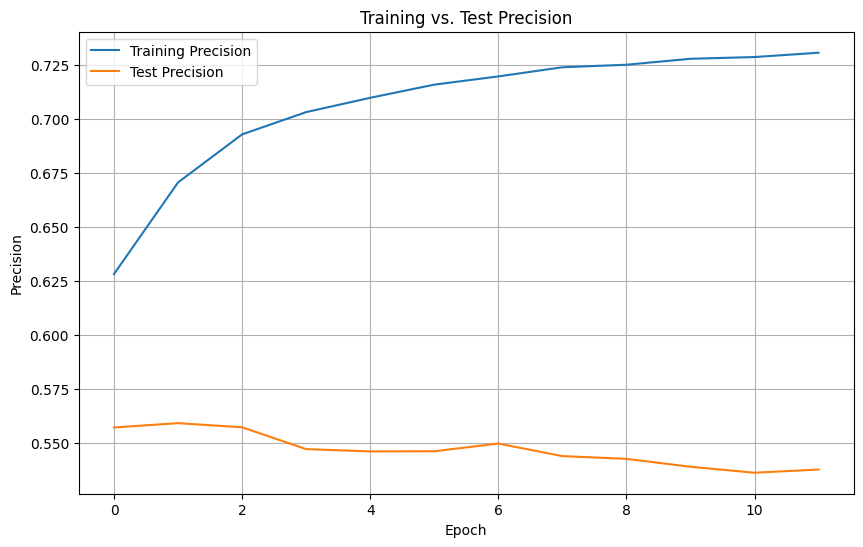

In [98]:
# Learning visualisation for the Deep Neural Network (DNN)
# The model is not actually training, as the precision and accuracy score are not improving on TRAIN/TEST with more Epochs

# Plotting accuracy
plt.figure(figsize=(10, 6))
plt.plot(best_history_nn['precision_1'], label='Training Precision')
plt.plot(best_history_nn['val_precision_1'], label='Test Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Training vs. Test Precision')
plt.legend()
plt.grid(True)
plt.show()

# 2) Different Decision rules to improve precision (varying threshold)

best model1 **(clf_best)**: Decision Tree (max_depth=7 - manually selected second-best model)

best model2 **(rf_best)**: Random Forest (n_estimators=100, max_depth=13)

## 2.1. Predicting probabilities (predict_proba), getting the distribution for probabilities, and new decision rules

In [99]:

# predicting probability instead of a lable

y_pred_test = rf_best.predict_proba(X_test)
y_pred_test_class1 = [k[1] for k in y_pred_test] # k[1] is the second element in the list of Class predictions

In [100]:
# example prediction of probabilities
y_pred_test

array([[0.59054993, 0.40945007],
       [0.5944781 , 0.4055219 ],
       [0.52602458, 0.47397542],
       ...,
       [0.44231934, 0.55768066],
       [0.43192432, 0.56807568],
       [0.42709831, 0.57290169]])

In [101]:
y_pred_test_class1_df = pd.DataFrame(y_pred_test_class1, columns=['Class1_probability'])
y_pred_test_class1_df.head()

,Class1_probability
0,0.409450
1,0.405522
2,0.473975
3,0.495109
4,0.474934


In [102]:
# Mean prediction is 0.54, median is 0.55, 75% quantile is 0.60
y_pred_test_class1_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Class1_probability,33163.0,0.487237,0.060192,0.275092,0.445081,0.485427,0.527555,0.746731


In [103]:
# Unconditional probability of a positive growth is 55.5%
y_test.sum()/y_test.count()

np.float64(0.5700931761300244)

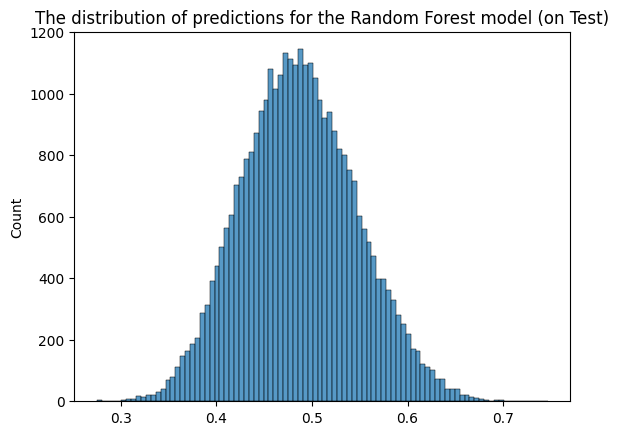

In [104]:
# perfect shape for a Random Forest predictions vs. a Decision Tree - it's an average across many trees (estimators)
sns.histplot(y_pred_test_class1)

# Add a title
plt.title('The distribution of predictions for the Random Forest model (on Test)')

# Show the plot
plt.show()

In [105]:
# tpr (True Positive Rate) vs. fpr (False Positive Rate) dataframe
# tp = True Positive
# tn = True Negative
# fp = False Positive
# fn = False Negative
# Decision Rule :  "y_pred>= Threshold" for Class "1"

# when only_even=True --> we'll have a step ==0.02 and leave only even records

def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    scores = []

    if only_even==False:
      thresholds = np.linspace(0, 1, 101) #[0, 0.01, 0.02, ...0.99,1.0]
    else:
      thresholds = np.linspace(0, 1, 51) #[0, 0.02, 0.04,  ...0.98,1.0]

    for t in thresholds:

        actual_positive = (y_true == 1)
        actual_negative = (y_true == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        if tp + fp > 0:
          precision = tp / (tp + fp)

        if tp + fn > 0:
          recall = tp / (tp + fn)

        if precision+recall > 0:
          f1_score = 2*precision*recall / (precision+recall)

        accuracy = (tp+tn) / (tp+tn+fp+fn)

        scores.append((t, tp, fp, fn, tn, precision, recall, accuracy, f1_score))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn','precision','recall', 'accuracy','f1_score']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores


In [106]:
df_scores = tpr_fpr_dataframe(y_test,
                              y_pred_test_class1,
                              only_even=True)

In [107]:
# full df_scores
df_scores

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
0,0.00,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
1,0.02,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
2,0.04,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
3,0.06,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
4,0.08,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
5,0.10,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
6,0.12,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
7,0.14,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
8,0.16,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000
9,0.18,18906,14257,0,0,0.570093,1.000000,0.570093,0.726190,1.000000,1.000000


In [108]:
df_scores[(df_scores.threshold>=0.5) & (df_scores.threshold<=0.8)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
25,0.50,7943,5477,10963,8780,0.591878,0.420131,0.504267,0.491431,0.420131,0.384162
26,0.52,5801,3790,13105,10467,0.604838,0.306834,0.490547,0.407131,0.306834,0.265834
27,0.54,3936,2459,14970,11798,0.615481,0.208188,0.474444,0.311134,0.208188,0.172477
28,0.56,2481,1474,16425,12783,0.627307,0.131228,0.460272,0.217051,0.131228,0.103388
29,0.58,1471,835,17435,13422,0.637901,0.077806,0.449085,0.138695,0.077806,0.058568
30,0.60,736,427,18170,13830,0.632846,0.038929,0.439224,0.073347,0.038929,0.029950
31,0.62,354,197,18552,14060,0.642468,0.018724,0.434641,0.036388,0.018724,0.013818
32,0.64,145,70,18761,14187,0.674419,0.007670,0.432168,0.015167,0.007670,0.004910
33,0.66,55,19,18851,14238,0.743243,0.002909,0.430992,0.005796,0.002909,0.001333
34,0.68,21,1,18885,14256,0.954545,0.001111,0.430510,0.002219,0.001111,0.000070


<Axes: title={'center': 'Precision vs. Recall for Random Forest with best max_depth'}, xlabel='threshold'>

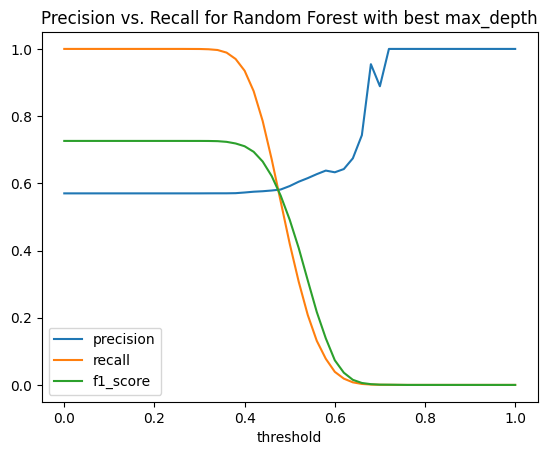

In [109]:
# Try to find high Precision score points

df_scores.plot.line(x='threshold',
                    y=['precision','recall', 'f1_score'],
                    title = 'Precision vs. Recall for Random Forest with best max_depth')

## 2.2) [Code Snippet 6] Defining new columns with Predictions in new_df: pred7..pred10
* pred7 and pred8 are 2 decision rules for the Decision Tree (best model with max_depth=15)
* pred9 and pred10 are 2 decision rules for the Random Forest (second best model)

In [110]:
# adding Decision Tree predictors (clf_best) to the dataset for 2 new rules based on thresholds


y_pred_all = clf_best.predict_proba(X_all)
y_pred_all_class1 = [k[1] for k in y_pred_all] #list of predictions for class "1"
y_pred_all_class1_array = np.array(y_pred_all_class1) # (Numpy Array) np.array of predictions for class "1" , converted from a list

# defining a new prediction vector is easy now, as the dimensions will match
new_df['proba_pred8'] = y_pred_all_class1_array
new_df['pred8_clf_second_best_rule_56'] = (y_pred_all_class1_array >= 0.56).astype(int)

new_df['proba_pred9'] = y_pred_all_class1_array
new_df['pred9_clf_second_best_rule_66'] = (y_pred_all_class1_array >= 0.66).astype(int)

In [111]:
# adding Random Forest predictors (rf_best)
rf_best

RandomForestClassifier(max_depth=13, n_jobs=-1, random_state=42)

In [112]:
# make predictions of probabilities using the Random Forest model (rf_best)

y_pred_all = rf_best.predict_proba(X_all)
y_pred_all_class1 = [k[1] for k in y_pred_all] #list of predictions for class "1"
y_pred_all_class1_array = np.array(y_pred_all_class1) # (Numpy Array) np.array of predictions for class "1" , converted from a list


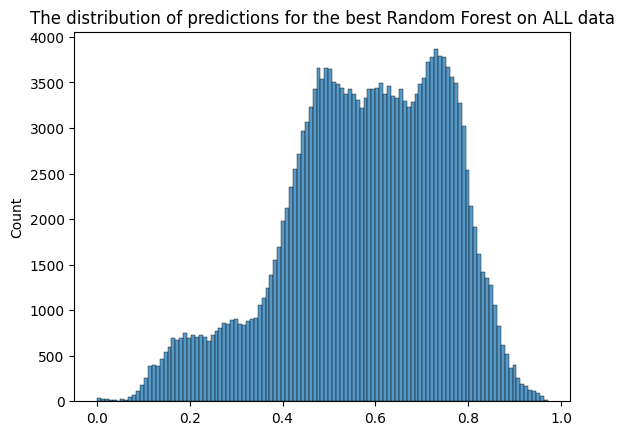

In [113]:
# PREDICTIONS ON A FULL DATASET - different from on a TRAINED SET (too optimistic? or just a bullish environment?)
sns.histplot(y_pred_all_class1)

# Add a title
plt.title('The distribution of predictions for the best Random Forest on ALL data')

# Show the plot
plt.show()

In [114]:
# adding Random Forest predictors (rf_best) to the dataset for 2 new rules, based on Thresholds
# defining a new prediction vector is easy now, as the dimensions will match
new_df['proba_pred10'] = y_pred_all_class1_array
new_df['pred10_rf_best_rule_55'] = (y_pred_all_class1_array >= 0.55).astype(int)

new_df['proba_pred11'] = y_pred_all_class1_array
new_df['pred11_rf_best_rule_65'] = (y_pred_all_class1_array >= 0.65).astype(int)

<Axes: >

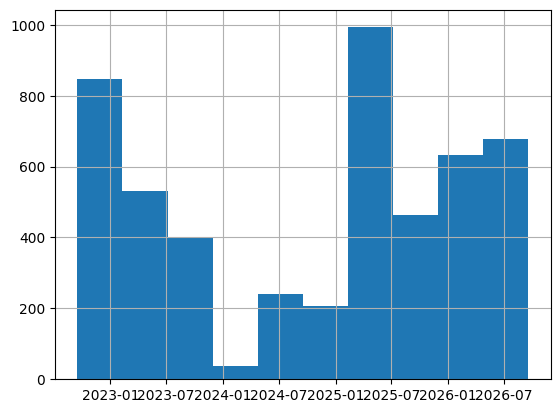

In [115]:
# Many positive predictions
new_df[(new_df.split=='test')&(new_df.pred10_rf_best_rule_55==1)].Date.hist()

<Axes: >

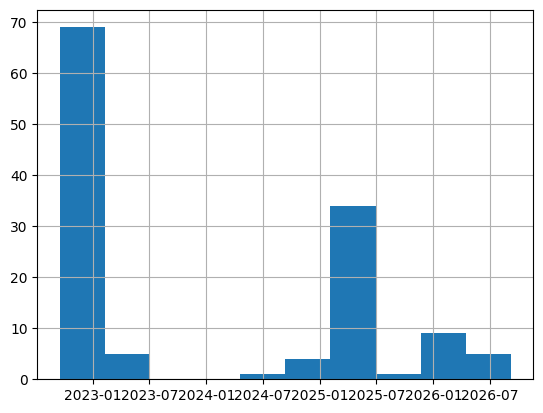

In [116]:
# Vs. less positives on higher-threshold rule
new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].Date.hist()

In [117]:
# sample of rare predictions with high threshold vs. other predictions
new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].sort_values(by='Date').sample(10)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,is_correct_pred6,is_correct_pred7,proba_pred8,pred8_clf_second_best_rule_56,proba_pred9,pred9_clf_second_best_rule_66,proba_pred10,pred10_rf_best_rule_55,proba_pred11,pred11_rf_best_rule_65
6735,492.382139,497.027253,488.666047,495.912415,8522604.0,0.0,0.0,SBIN.NS,2022,October,...,1,1,0.568367,1,0.568367,0,0.664757,1,0.664757,1
3924,190.717678,193.847772,187.084027,188.950226,27236100.0,0.0,0.0,AVGO,2025,March,...,0,1,0.827160,1,0.827160,1,0.661894,1,0.661894,1
5855,583.292524,586.058692,568.447447,570.014954,398908.0,0.0,0.0,MC.PA,2022,October,...,1,1,0.568367,1,0.568367,0,0.673750,1,0.673750,1
6722,526.523778,533.259194,522.110919,527.034729,11869435.0,0.0,0.0,SBIN.NS,2022,September,...,1,1,0.568367,1,0.568367,0,0.658492,1,0.658492,1
3197,4.542115,4.590718,4.493513,4.502349,3279200.0,0.0,0.0,IDEXY,2022,September,...,1,1,0.568367,1,0.568367,0,0.683484,1,0.683484,1
7282,766.081471,769.066677,760.255585,763.818542,7273098.0,0.0,0.0,SBIN.NS,2025,January,...,0,0,0.763881,1,0.763881,1,0.656432,1,0.656432,1
10737,102.526584,105.530219,101.391064,101.821465,33387100.0,0.0,0.0,JPM,2022,October,...,1,1,0.568367,1,0.568367,0,0.650979,1,0.650979,1
6735,272.525968,273.641009,270.915343,271.452209,7546587.0,0.0,0.0,ITC.NS,2022,October,...,1,1,0.568367,1,0.568367,0,0.654024,1,0.654024,1
3193,4.502350,4.537697,4.405145,4.413982,1528000.0,0.0,0.0,IDEXY,2022,September,...,1,1,0.568367,1,0.568367,0,0.725767,1,0.725767,1
6543,2227.554033,2235.474226,2201.813409,2203.793457,50065.0,0.0,0.0,RMS.PA,2025,June,...,0,0,0.763881,1,0.763881,1,0.672542,1,0.672542,1


In [118]:
# List of ALL current predictions
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds',
 'pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65']

In [119]:
# Pred 11: How many positive prediction per day (out of 33 stocks possible)
pred11_daily_positive_count = pd.DataFrame(new_df[(new_df.split=='test')&(new_df.pred11_rf_best_rule_65==1)].groupby('Date')['pred11_rf_best_rule_65'].count())

In [120]:
# Pred 10: How many positive prediction per day (out of 33 stocks possible)
pred10_daily_positive_count = pd.DataFrame(new_df[(new_df.split=='test')&(new_df.pred10_rf_best_rule_55==1)].groupby('Date')['pred10_rf_best_rule_55'].count())

In [121]:
# Unique trading days on Test (4 years)
new_df[(new_df.split=='test')].Date.nunique()

1040

In [122]:
pred10_daily_positive_count

,pred10_rf_best_rule_55
Date,
2022-09-16,15
2022-09-19,12
2022-09-20,15
2022-09-21,14
2022-09-22,19
...,...
2026-09-11,1
2026-09-15,9
2026-09-16,4


array([[<Axes: title={'center': 'pred10_rf_best_rule_55'}>]], dtype=object)

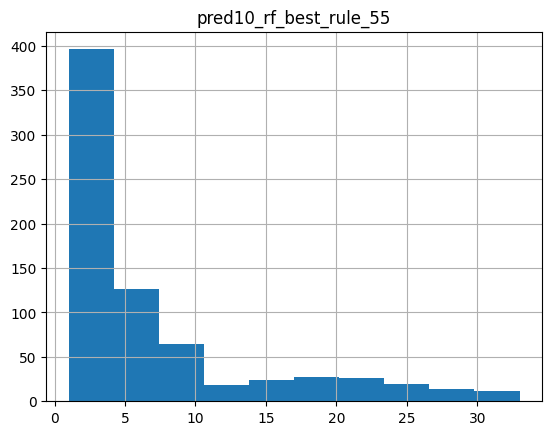

In [123]:
pred10_daily_positive_count.hist()

In [124]:
# 75% cases we have not more than 3 bets of $100
pred10_daily_positive_count.describe().T

,count,mean,std,min,25%,50%,75%,max
pred10_rf_best_rule_55,726.0,6.933884,7.550915,1.0,2.0,4.0,8.0,33.0


array([[<Axes: title={'center': 'pred11_rf_best_rule_65'}>]], dtype=object)

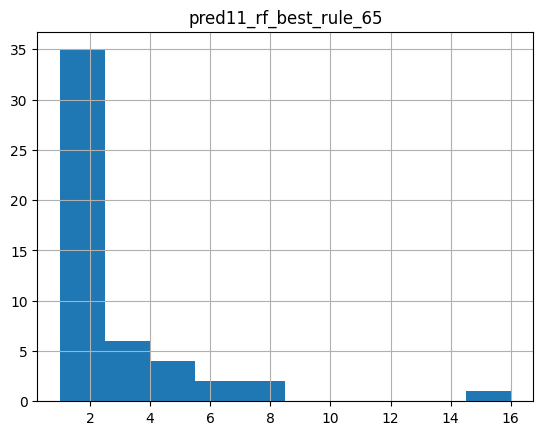

In [125]:
pred11_daily_positive_count.hist()

In [126]:
pred11_daily_positive_count.describe().T

,count,mean,std,min,25%,50%,75%,max
pred11_rf_best_rule_65,50.0,2.56,2.556784,1.0,1.0,2.0,3.0,16.0


## 2.3) Agg. stats on ALL predictions

In [127]:
# let's review the Predictions:
PREDICTIONS, IS_CORRECT = get_predictions_correctness(new_df, to_predict=to_predict)


Prediction columns founded: ['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp', 'pred3_manual_dgs10_5', 'pred4_manual_dgs10_fedfunds', 'pred5_clf_10', 'pred6_clf_4', 'pred7_clf_second_best', 'pred8_clf_second_best_rule_56', 'pred9_clf_second_best_rule_66', 'pred10_rf_best_rule_55', 'pred11_rf_best_rule_65']
Created columns is_correct: ['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2', 'is_correct_pred3', 'is_correct_pred4', 'is_correct_pred5', 'is_correct_pred6', 'is_correct_pred7', 'is_correct_pred8', 'is_correct_pred9', 'is_correct_pred10', 'is_correct_pred11']
Precision on TEST set for each prediction:
Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    520
0    401
Name: count, dtype: int64
is_correct_pred0
1    0.564604
0    0.435396
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    11086
0     8072
Name: count, dtype:

In [128]:
# check approx. periods : Train, Valid , Test
new_df.groupby('split').Date.agg(['min','max'])

,min,max
split,,
test,2022-09-16,2026-09-18
train,2000-01-03,2018-09-13
validation,2018-09-14,2022-09-15


In [129]:
# Extract number from the prediction column

# Example string
example_string = "pred10_rf_best_rule_60"

# Split the string by '_'
parts = example_string.split('_')

# Extract the part with 'pred' and remove the 'pred' prefix
pred_number = parts[0].replace('pred', '')

# Print the result
print(pred_number)

# Print in one line
print(int(example_string.split('_')[0].replace('pred', '')))


10
10


In [130]:
# all predictions
PREDICTIONS

['pred0_manual_cci',
 'pred1_manual_prev_g1',
 'pred2_manual_prev_g1_and_snp',
 'pred3_manual_dgs10_5',
 'pred4_manual_dgs10_fedfunds',
 'pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65']

In [131]:
# all predictions on MODELS (not manual predictions)
PREDICTIONS_ON_MODELS = [p for p in PREDICTIONS if int(p.split('_')[0].replace('pred', ''))>=5]
PREDICTIONS_ON_MODELS

['pred5_clf_10',
 'pred6_clf_4',
 'pred7_clf_second_best',
 'pred8_clf_second_best_rule_56',
 'pred9_clf_second_best_rule_66',
 'pred10_rf_best_rule_55',
 'pred11_rf_best_rule_65']

In [132]:
# all predictions on Models - correctness
IS_CORRECT_ON_MODELS = [p for p in IS_CORRECT if int(p.replace('is_correct_pred', ''))>=5]
IS_CORRECT_ON_MODELS

['is_correct_pred5',
 'is_correct_pred6',
 'is_correct_pred7',
 'is_correct_pred8',
 'is_correct_pred9',
 'is_correct_pred10',
 'is_correct_pred11']

In [133]:
# predictions on models
# pred10_rf_best_rule_60: ONLY 2% of TEST cases predicted with high confidence of growth
new_df.groupby('split')[PREDICTIONS_ON_MODELS].agg(['count','sum','mean']).T

split                                        test          train    validation
pred5_clf_10                  count  33163.000000  136842.000000  32287.000000
                              sum     9558.000000   99883.000000  21664.000000
                              mean       0.288213       0.729915      0.670982
pred6_clf_4                   count  33163.000000  136842.000000  32287.000000
                              sum     6677.000000  113726.000000  28191.000000
                              mean       0.201339       0.831075      0.873138
pred7_clf_second_best         count  33163.000000  136842.000000  32287.000000
                              sum     4416.000000  109184.000000  24733.000000
                              mean       0.133160       0.797884      0.766036
pred8_clf_second_best_rule_56 count  33163.000000  136842.000000  32287.000000
                              sum     4403.000000   90749.000000  20427.000000
                              mean       0.132768       0.663166      0.632669
pred9_clf_second_best_rule_66 count  33163.000000  136842.000000  32287.000000
                              sum     2405.000000   60719.000000  18290.000000
                              mean       0.072521       0.443716      0.566482
pred10_rf_best_rule_55        count  33163.000000  136842.000000  32287.000000
                              sum     5034.000000   90794.000000  21068.000000
                              mean       0.151796       0.663495      0.652523
pred11_rf_best_rule_65        count  33163.000000  136842.000000  32287.000000
                              sum      128.000000   60162.000000  16618.000000
                              mean       0.003860       0.439646      0.514696

In [134]:
# 11 predictions stats (check TEST set)
new_df.groupby('split')[PREDICTIONS].agg(['count','sum','mean']).T

split                                        test          train    validation
pred0_manual_cci              count  33163.000000  136842.000000  32287.000000
                              sum      921.000000    3678.000000    772.000000
                              mean       0.027772       0.026878      0.023911
pred1_manual_prev_g1          count  33163.000000  136842.000000  32287.000000
                              sum    19158.000000   80980.000000  19480.000000
                              mean       0.577692       0.591777      0.603339
pred2_manual_prev_g1_and_snp  count  33163.000000  136842.000000  32287.000000
                              sum    15244.000000   61181.000000  15761.000000
                              mean       0.459669       0.447092      0.488153
pred3_manual_dgs10_5          count  33163.000000  136842.000000  32287.000000
                              sum    15910.000000  104228.000000  32287.000000
                              mean       0.479752       0.761667      1.000000
pred4_manual_dgs10_fedfunds   count  33163.000000  136842.000000  32287.000000
                              sum    15921.000000   30611.000000      0.000000
                              mean       0.480083       0.223696      0.000000
pred5_clf_10                  count  33163.000000  136842.000000  32287.000000
                              sum     9558.000000   99883.000000  21664.000000
                              mean       0.288213       0.729915      0.670982
pred6_clf_4                   count  33163.000000  136842.000000  32287.000000
                              sum     6677.000000  113726.000000  28191.000000
                              mean       0.201339       0.831075      0.873138
pred7_clf_second_best         count  33163.000000  136842.000000  32287.000000
                              sum     4416.000000  109184.000000  24733.000000
                              mean       0.133160       0.797884      0.766036
pred8_clf_second_best_rule_56 count  33163.000000  136842.000000  32287.000000
                              sum     4403.000000   90749.000000  20427.000000
                              mean       0.132768       0.663166      0.632669
pred9_clf_second_best_rule_66 count  33163.000000  136842.000000  32287.000000
                              sum     2405.000000   60719.000000  18290.000000
                              mean       0.072521       0.443716      0.566482
pred10_rf_best_rule_55        count  33163.000000  136842.000000  32287.000000
                              sum     5034.000000   90794.000000  21068.000000
                              mean       0.151796       0.663495      0.652523
pred11_rf_best_rule_65        count  33163.000000  136842.000000  32287.000000
                              sum      128.000000   60162.000000  16618.000000
                              mean       0.003860       0.439646      0.514696

# 3) Trading Simulations

* create simulation 1 features: like "sim1_pred0" ... "sim1_predLast"

## 3.1) Investing $100 on every positive prediction
* fees = 0.1% for each buy and sell operation ==> 0.2% for buy+sell operation

In [135]:
# current prediction
pred = 'pred5_clf_10'

In [136]:
# Total Number of Investment Opportunities
new_df[new_df.split=='test'].Close_x.count()

np.int64(33163)

In [137]:
# Total Number of Days (~4 years of trading)
new_df[new_df.split=='test'].Date.nunique()

1040

In [138]:
# check actual future growth with 'growth_future_5d', correctness of the prediction with 'is_positive_growth_5d_future'
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [139]:
# Sample
new_df[['growth_future_30d','is_positive_growth_30d_future',pred]].sample(5)

,growth_future_30d,is_positive_growth_30d_future,pred5_clf_10
2648,0.937563,0,1
4168,0.932039,0,1
3738,0.928135,0,1
2803,0.974366,0,0
475,1.228008,1,1


In [140]:
# GROSS REVENUE: ONLY when current_prediction equals to 1: invest $100 into that stock (buy), and sell in 1week (sell)
new_df['sim1_gross_rev_pred6'] = new_df[pred] * 100 * (new_df['growth_future_30d']-1)

In [141]:
# FEES: 0.1% for each operation , 0.2% for buy+sell ONLY when current_prediction equals to one
new_df['sim1_fees_pred6'] = -new_df[pred] * 100 * 0.002

In [142]:
# NET REVENUE: GROSS_REVENUE + FEES
new_df['sim1_net_rev_pred6'] = new_df['sim1_gross_rev_pred6'] + new_df['sim1_fees_pred6']

In [143]:
# sample of individual results
COLUMNS_FIN_RESULT = ['Date','Ticker','Close_x']+TO_PREDICT+ [pred,  'sim1_gross_rev_pred6','sim1_fees_pred6','sim1_net_rev_pred6']
new_df[(new_df.split=='test')&(new_df[pred]==1)][COLUMNS_FIN_RESULT].sample(5)

,Date,Ticker,Close_x,growth_future_30d,is_positive_growth_30d_future,pred5_clf_10,sim1_gross_rev_pred6,sim1_fees_pred6,sim1_net_rev_pred6
6229,2023-12-11,INFY,16.042799,1.153934,1,1,15.393446,-0.2,15.193446
6325,2024-08-09,RMS.PA,1975.135620,0.957341,0,1,-4.265870,-0.2,-4.465870
7108,2024-08-07,BRK-B,427.019989,1.076554,1,1,7.655380,-0.2,7.455380
7286,2024-08-28,SAP,211.312790,1.036141,1,1,3.614071,-0.2,3.414071
7029,2024-04-12,SIE.DE,165.200500,1.036256,1,1,3.625623,-0.2,3.425623


In [144]:
# DAILY INVESTMENTS COUNT
filter_test_and_positive_pred = (new_df.split=='test')&(new_df[pred]==1)
df_investments_count_daily = pd.DataFrame(new_df[filter_test_and_positive_pred].groupby('Date')[pred].count())
sim1_avg_investments_per_day = df_investments_count_daily[pred].quantile(0.75)  # 75% case - how many $100 investments per day do we have?
print(sim1_avg_investments_per_day)

16.0


In [145]:
# Distribution: how many times do we trade daily (for the current Prediction)?
df_investments_count_daily.describe().T

,count,mean,std,min,25%,50%,75%,max
pred5_clf_10,937.0,10.20064,9.53078,1.0,2.0,7.0,16.0,33.0


In [146]:
new_df[(new_df.split=='test')&(new_df[pred]==1)][['sim1_gross_rev_pred6','sim1_fees_pred6','sim1_net_rev_pred6']].sum()

,0
sim1_gross_rev_pred6,32081.055924
sim1_fees_pred6,-1911.600000
sim1_net_rev_pred6,30183.455924


### 3.1.2 Calculate fin. results for all fields
* Simplified and approximate calculation

In [147]:
# Calculate fin. result for ALL predictions (manual and produced by models)

sim1_results = [] # results in Array

# Iterate over all predictions
for pred in PREDICTIONS:
  print(f'Calculating sumulation for prediction {pred}:')
  print(f"    Count times of investment {len(new_df[(new_df.split=='test')&(new_df[pred]==1)])} out of {len(new_df[(new_df.split=='test')])} TEST records")

  # Prefix: e.g. pred1 or pred10
  pred_prefix= pred.split('_')[0]

  # Fin. result columns: define new records for EACH positive prediction
  new_df['sim1_gross_rev_'+pred_prefix] = new_df[pred] * 100 * (new_df['growth_future_30d']-1)
  new_df['sim1_fees_'+pred_prefix] = -new_df[pred] * 100 * 0.002
  new_df['sim1_net_rev_'+pred_prefix] = new_df['sim1_gross_rev_'+pred_prefix] + new_df['sim1_fees_'+pred_prefix]

  # calculate agg. results for each PREDICTION columns (pred) on TEST
  filter_test_and_positive_pred = (new_df.split=='test')&(new_df[pred]==1) # filter records on TEST set, when current prediction is 1 (we invest $100 for 1 week ahead - 5 periods)
  sim1_count_investments = len(new_df[filter_test_and_positive_pred])
  sim1_gross_rev = new_df[filter_test_and_positive_pred]['sim1_gross_rev_'+pred_prefix].sum()
  sim1_fees = new_df[filter_test_and_positive_pred]['sim1_fees_'+pred_prefix].sum()
  sim1_net_rev = new_df[filter_test_and_positive_pred]['sim1_net_rev_'+pred_prefix].sum()

  if sim1_gross_rev>0:
    sim1_fees_percentage = -sim1_fees/sim1_gross_rev
  else:
    sim1_fees_percentage = None

  if sim1_count_investments>0:
    sim1_average_net_revenue = sim1_net_rev/sim1_count_investments
  else:
    sim1_average_net_revenue = None

  # APPROXIMATE CAPITAL REQUIRED and CAGR Calculation
  df_investments_count_daily = pd.DataFrame(new_df[filter_test_and_positive_pred].groupby('Date')[pred].count())
  sim1_avg_investments_per_day = df_investments_count_daily[pred].mean()
  sim1_q75_investments_per_day = df_investments_count_daily[pred].quantile(0.75)  # 75% case - how many $100 investments per day do we have?
  # df_investments_count_daily[pred].mean()
  sim1_capital = 100 * 30 * sim1_q75_investments_per_day # 30 days in a row with positive predictions

  # CAGR: average growth per year. E.g. if you have 1.5 return (50% growth in 4 years) --> (1.5)**(1/4) = 1.106 or 10.6% average
  sim1_CAGR = ((sim1_capital+sim1_net_rev)/sim1_capital)**(1/4)

  # append to DF
  sim1_results.append((pred,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR))


  # output for all predictions with some positive predictions
  if  sim1_count_investments>1:
    print(f"    Financial Result: \n {new_df[filter_test_and_positive_pred][['sim1_gross_rev_'+pred_prefix,'sim1_fees_'+pred_prefix,'sim1_net_rev_'+pred_prefix]].sum()}")
    print(f"        Count Investments in 4 years (on TEST): {sim1_count_investments}")
    print(f"        Gross Revenue: ${int(sim1_gross_rev)}")
    print(f"        Fees (0.2% for buy+sell): ${int(-sim1_fees)}")
    print(f"        Net Revenue: ${int(sim1_net_rev)}")
    print(f"        Fees are {int(-100.0*sim1_fees/sim1_gross_rev)} % from Gross Revenue")
    print(f"        Capital Required : ${int(sim1_capital)} (Vbegin)")
    print(f"        Final value (Vbegin + Net_revenue) : ${int(sim1_capital + sim1_net_rev)} (Vfinal)")

    print(f"        Average CAGR on TEST (4 years) : {np.round(sim1_CAGR,3)}, or {np.round(100.0*(sim1_CAGR-1),1)}% ")

    print(f"        Average daily stats: ")
    print(f"            Average net revenue per investment: ${np.round(sim1_net_rev/sim1_count_investments,2)} ")
    print(f"            Average investments per day: {int(np.round(sim1_avg_investments_per_day))} ")
    print(f"            Q75 investments per day: {int(np.round(sim1_q75_investments_per_day))} ")
    print('=============================================+')


# results in a DataFrame from an Array
columns_simulation = ['prediction', 'sim1_count_investments', 'sim1_gross_rev', 'sim1_fees', 'sim1_net_rev', 'sim1_fees_percentage','sim1_average_net_revenue','sim1_avg_investments_per_day','sim1_capital','sim1_CAGR']

df_sim1_results = pd.DataFrame(sim1_results,columns=columns_simulation)

Calculating sumulation for prediction pred0_manual_cci:
    Count times of investment 921 out of 33163 TEST records
    Financial Result: 
 sim1_gross_rev_pred0    1839.392853
sim1_fees_pred0         -184.200000
sim1_net_rev_pred0      1656.192853
dtype: float64
        Count Investments in 4 years (on TEST): 921
        Gross Revenue: $1839
        Fees (0.2% for buy+sell): $184
        Net Revenue: $1656
        Fees are 10 % from Gross Revenue
        Capital Required : $6000 (Vbegin)
        Final value (Vbegin + Net_revenue) : $7656 (Vfinal)
        Average CAGR on TEST (4 years) : 1.063, or 6.3% 
        Average daily stats: 
            Average net revenue per investment: $1.8 
            Average investments per day: 2 
            Q75 investments per day: 2 
=============================================+
Calculating sumulation for prediction pred1_manual_prev_g1:
    Count times of investment 19158 out of 33163 TEST records
    Financial Result: 
 sim1_gross_rev_pred1    44647

In [148]:
df_sim1_results['sim1_growth_capital_4y'] = (df_sim1_results.sim1_net_rev+df_sim1_results.sim1_capital) / df_sim1_results.sim1_capital

In [149]:
# final comparison
df_sim1_results

,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y
0,pred0_manual_cci,921,1839.392853,-184.2,1656.192853,0.100142,1.798255,1.875764,6000.0,1.062834,1.276032
1,pred1_manual_prev_g1,19158,44647.366885,-3831.6,40918.366885,0.085819,2.135837,18.421154,72000.0,1.119072,1.568311
2,pred2_manual_prev_g1_and_snp,15244,33808.094246,-3048.8,30853.894246,0.090180,2.024003,21.715100,75000.0,1.089962,1.411385
3,pred3_manual_dgs10_5,15910,40723.803021,-3182.0,37541.803021,0.078136,2.359636,31.947791,99000.0,1.083696,1.379210
4,pred4_manual_dgs10_fedfunds,15921,18532.879990,-3184.2,15546.679990,0.171814,0.976489,31.905812,99000.0,1.037139,1.157037
5,pred5_clf_10,9558,32081.055924,-1911.6,30183.455924,0.059587,3.157926,10.200640,48000.0,1.129714,1.628822
6,pred6_clf_4,6677,22383.446047,-1335.4,21050.646047,0.059660,3.152710,30.350000,99000.0,1.049379,1.212633
7,pred7_clf_second_best,4416,15722.280309,-883.2,14841.680309,0.056175,3.360888,9.395745,39000.0,1.083961,1.380556
8,pred8_clf_second_best_rule_56,4403,15702.377757,-880.6,14824.377757,0.056081,3.366881,9.388060,39000.0,1.083874,1.380112
9,pred9_clf_second_best_rule_66,2405,6655.388477,-481.0,6174.388477,0.072272,2.567313,5.593023,21000.0,1.066560,1.294018


In [150]:
# Create the scatter plot
fig = px.scatter(
    df_sim1_results.dropna(),
    x='sim1_avg_investments_per_day',
    y='sim1_CAGR',
    size='sim1_growth_capital_4y',  # Use the 'size' parameter for sim1_CAGR
    text='prediction',
    title='Compound Annual Growth vs. Time spent (Average investments per day)',
    labels={'sim1_capital': 'Initial Capital Requirement', 'growth_capital_4y': '4-Year Capital Growth'}
)

# Update the layout to improve readability of the annotations
fig.update_traces(textposition='top center')

# Show the plot
fig.show()

## 3.2. Advanced Simulation
* to_predict = 'is_positive_growth_30d_future'
* invest ~3% of capital each day (sell positions from 30 days ago), REINVEST PREVIOUS GAINS
* use predict_proba predictions
* select top1..3..x predictions > threshold (0.53)
* invest proportionally the prediction
* stop loss y%
* take profit z%
* Not included: portfolio optimization

### 3.2.1) [Code Snippet 1] Define rank of prediction (daily)
*  to be used later for top 1..k

In [151]:
# https://stackoverflow.com/questions/17775935/sql-like-window-functions-in-pandas-row-numbering-in-python-pandas-dataframe
# rank of prediction

new_df["pred9_rank"] = new_df.groupby("Date")["proba_pred9"].rank(method="first", ascending=False)

new_df["pred10_rank"] = new_df.groupby("Date")["proba_pred10"].rank(method="first", ascending=False)


In [152]:
# CHECK RANK FOR 1 DAY (Random Forest):
  # we have predictions for all 33 stocks
first_trading_day_2026 = new_df[new_df.Date>='2026-01-01'].Date.unique().astype(str)[0]
first_trading_day_2026
print(f'First trading day in 2026: {first_trading_day_2026}, count predictions = {len(new_df[new_df.Date==first_trading_day_2026])}')

First trading day in 2026: 2026-01-02, count predictions = 33


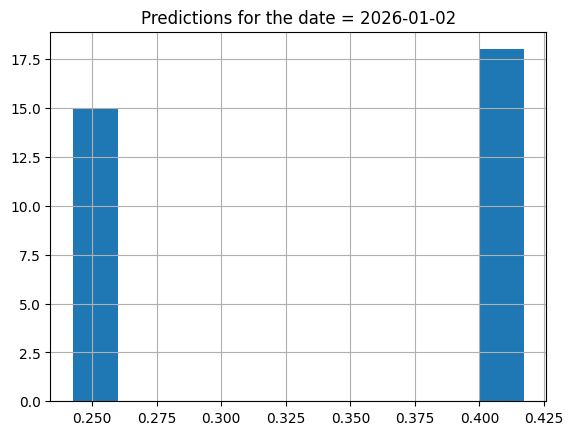

In [153]:
# Decision Tree's predictions are not very smooth - either too small or too big
new_df[new_df.Date==first_trading_day_2026].proba_pred9.hist()
plt.title(f'Predictions for the date = {first_trading_day_2026}')
# Show the plot
plt.show()

In [154]:
new_df[new_df.Date==first_trading_day_2026][['Date','Ticker', 'Close_x','proba_pred9','pred9_rank']].sort_values(by='pred9_rank').head(5)

,Date,Ticker,Close_x,proba_pred9,pred9_rank
10029,2026-01-02,MSFT,469.958496,0.417228,1.0
11355,2026-01-02,AAPL,270.274353,0.417228,2.0
7460,2026-01-02,BRK-B,496.850006,0.417228,3.0
6681,2026-01-02,MC.PA,631.502625,0.417228,4.0
6681,2026-01-02,RMS.PA,2083.010254,0.417228,5.0


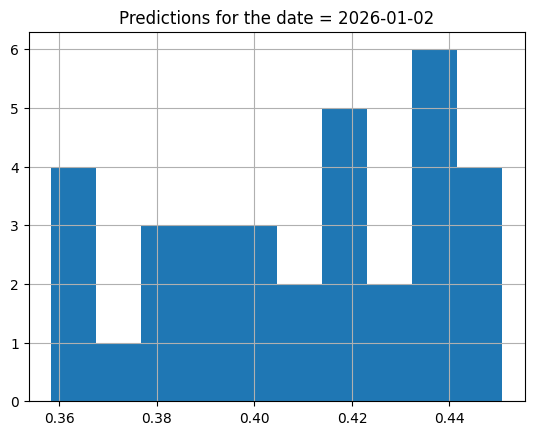

In [155]:
# Random Forest's predictions are more spreaded across the range - rank() function will work
new_df[new_df.Date==first_trading_day_2026].proba_pred10.hist()
plt.title(f'Predictions for the date = {first_trading_day_2026}')
# Show the plot
plt.show()

In [156]:
# It is quite different vs. a single Decision tree (proba_pred9 vs. proba_pred10)
new_df[new_df.Date==first_trading_day_2026][['Date','Ticker', 'Close_x','proba_pred9','proba_pred10','pred10_rank']].sort_values(by='pred10_rank').head(5)

,Date,Ticker,Close_x,proba_pred9,proba_pred10,pred10_rank
7531,2026-01-02,RELIANCE.NS,1584.971802,0.417228,0.450790,1.0
6480,2026-01-02,IBN,29.741001,0.417228,0.449583,2.0
11260,2026-01-02,NVO,49.898952,0.242579,0.447619,3.0
899,2026-01-02,LICI.NS,420.566406,0.417228,0.446385,4.0
10029,2026-01-02,MSFT,469.958496,0.417228,0.438155,5.0


In [157]:
# OUTCOME: let's use pred10_proba for Advanced simulations

### 3.2.2 Define Min(Low) for the next 5 days and Max(High) for the next 5 days
* Assymetric! distributions for Max_High_Next_5 / Adj_close_today vs. Min_Low_Next_5/Adj_close_today

In [158]:
# Sort the DataFrame by Ticker and Date
new_df = new_df.sort_values(by=['Ticker', 'Date'])

In [159]:
new_df['growth_future_30d'].describe().T

,growth_future_30d
count,201302.000000
mean,1.023448
std,0.115613
min,0.246131
25%,0.961182
50%,1.020618
75%,1.082153
max,5.179688


In [160]:
# take profit if growth >=19% ?
new_df['growth_future_30d'].quantile(0.95)

np.float64(1.2002490048643628)

In [161]:
# stop loss when -9% ?
new_df['growth_future_30d'].quantile(0.1)

np.float64(0.8989314474466191)

In [162]:
# check a sample on the test dataset
new_df[new_df.split=='test'][['Date','High','Low','Close_x','Ticker','ticker_type','growth_future_30d']].sample(10)

,Date,High,Low,Close_x,Ticker,ticker_type,growth_future_30d
5929,2023-01-20,356.247495,350.213383,355.873291,OR.PA,EU,0.998554
112,2022-10-27,284.209570,282.878384,283.139862,LICI.NS,INDIA,1.128117
10701,2023-10-10,85.668720,84.256799,85.274483,NVO,EU,1.105042
475,2024-04-19,468.518015,454.922852,466.743683,LICI.NS,INDIA,0.953303
4176,2026-08-27,16.830000,16.670000,16.719999,IDEXY,EU,NaN
5052,2022-10-27,1898.046439,1876.918043,1890.538452,LT.NS,INDIA,1.096739
10645,2023-07-21,75.801257,74.879694,75.577713,NVO,EU,1.148257
6228,2024-03-22,412.347174,407.176843,410.449799,OR.PA,EU,1.049174
7510,2026-03-06,229.250000,221.149994,224.800003,SIE.DE,EU,1.074733
3650,2022-09-16,187.937281,182.507243,187.433060,V,US,1.082980


In [163]:
# Define a function to get the rolling max High and min Low for the next 30 trading days

# Sort the DataFrame: Sorting by Ticker and Date ensures that we are looking at each ticker's data in chronological order.
# Rolling window calculation: We use the rolling method with a window of 30 to calculate the maximum high and minimum low over the next 5 days.
# The shift method is used to align these values correctly with the current row.

def rolling_max_min(df, window=30):
    # high/low in 30 days
    df['Max_High_Next_30'] = df['High'].rolling(window=window, min_periods=1).max().shift(-window+1)
    df['Min_Low_Next_30'] = df['Low'].rolling(window=window, min_periods=1).min().shift(-window+1)

    # low in 1 day (for lower entry)
    df['Min_Low_Next_1'] = df['Low'].rolling(window=1, min_periods=1).min().shift(-1)
    return df

In [164]:
# Apply the function to each group of Ticker
# Important!: need to drop index from groupby operation (reset_index) - so that you can merge that afterwards
result = new_df[new_df.split=='test'][['Date','High','Low','Close_x','Ticker']].groupby('Ticker').apply(rolling_max_min).reset_index(drop=True)
result.head(30)

/tmp/ipykernel_33555/1191106210.py:3: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,Date,High,Low,Close_x,Ticker,Max_High_Next_30,Min_Low_Next_30,Min_Low_Next_1
0,2022-09-16,148.449610,145.526707,147.812057,AAPL,155.698036,131.795010,146.242747
1,2022-09-19,151.598107,146.242747,151.519638,AAPL,155.698036,131.795010,150.146447
2,2022-09-20,155.050629,150.146447,153.893234,AAPL,155.698036,131.795010,150.656535
3,2022-09-21,155.698036,150.656535,150.774231,AAPL,155.698036,131.795010,148.018071
4,2022-09-22,151.509847,148.018071,149.813004,AAPL,154.481806,131.795010,145.713097
5,2022-09-23,148.567335,145.713097,147.547256,AAPL,154.481806,131.795010,146.772387
6,2022-09-26,150.823247,146.772387,147.880737,AAPL,154.481806,131.795010,147.076479
7,2022-09-27,151.755075,147.076479,148.851791,AAPL,154.481806,131.795010,142.064398
8,2022-09-28,147.753255,142.064398,146.968582,AAPL,154.481806,131.795010,137.984109
9,2022-09-29,143.908372,137.984109,139.749619,AAPL,154.481806,131.795010,135.355487


In [165]:
result[result.Ticker=='AAPL'].tail(10)

,Date,High,Low,Close_x,Ticker,Max_High_Next_30,Min_Low_Next_30,Min_Low_Next_1
995,2026-09-04,328.929993,317.859985,319.970001,AAPL,NaN,NaN,314.899994
996,2026-09-08,320.700012,314.899994,316.220001,AAPL,NaN,NaN,309.899994
997,2026-09-09,319.149994,309.899994,315.339996,AAPL,NaN,NaN,316.510010
998,2026-09-10,326.739990,316.510010,326.570007,AAPL,NaN,NaN,326.299988
999,2026-09-11,336.220001,326.299988,332.269989,AAPL,NaN,NaN,331.339996
1000,2026-09-14,335.500000,331.339996,333.079987,AAPL,NaN,NaN,328.350006
1001,2026-09-15,331.779999,328.350006,331.339996,AAPL,NaN,NaN,330.700012
1002,2026-09-16,335.480011,330.700012,332.410004,AAPL,NaN,NaN,330.179993
1003,2026-09-17,338.339996,330.179993,337.000000,AAPL,NaN,NaN,332.529999
1004,2026-09-18,338.489990,332.529999,336.130005,AAPL,NaN,NaN,NaN


In [166]:
# Calculate the ratios + safe divide
result['Ratio_MaxHighNext30_to_Close'] = np.where(result['Close_x'] == 0, np.nan, result['Max_High_Next_30']/result['Close_x'])
result['Ratio_MinLowNext30_to_Close'] =  np.where(result['Close_x'] == 0, np.nan,  result['Min_Low_Next_30']/result['Close_x'])

result['Ratio_MinLowNext1_to_Close'] =  np.where(result['Close_x'] == 0, np.nan,  result['Min_Low_Next_1']/result['Close_x'])

In [167]:
result[result.Ticker=='AAPL'].head(10)

,Date,High,Low,Close_x,Ticker,Max_High_Next_30,Min_Low_Next_30,Min_Low_Next_1,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close
0,2022-09-16,148.449610,145.526707,147.812057,AAPL,155.698036,131.79501,146.242747,1.053351,0.891639,0.989383
1,2022-09-19,151.598107,146.242747,151.519638,AAPL,155.698036,131.79501,150.146447,1.027577,0.869821,0.990937
2,2022-09-20,155.050629,150.146447,153.893234,AAPL,155.698036,131.79501,150.656535,1.011728,0.856405,0.978968
3,2022-09-21,155.698036,150.656535,150.774231,AAPL,155.698036,131.79501,148.018071,1.032657,0.874122,0.981720
4,2022-09-22,151.509847,148.018071,149.813004,AAPL,154.481806,131.79501,145.713097,1.031164,0.879730,0.972633
5,2022-09-23,148.567335,145.713097,147.547256,AAPL,154.481806,131.79501,146.772387,1.046999,0.893239,0.994748
6,2022-09-26,150.823247,146.772387,147.880737,AAPL,154.481806,131.79501,147.076479,1.044638,0.891225,0.994561
7,2022-09-27,151.755075,147.076479,148.851791,AAPL,154.481806,131.79501,142.064398,1.037823,0.885411,0.954402
8,2022-09-28,147.753255,142.064398,146.968582,AAPL,154.481806,131.79501,137.984109,1.051121,0.896756,0.938868
9,2022-09-29,143.908372,137.984109,139.749619,AAPL,154.481806,131.79501,135.355487,1.105418,0.943080,0.968557


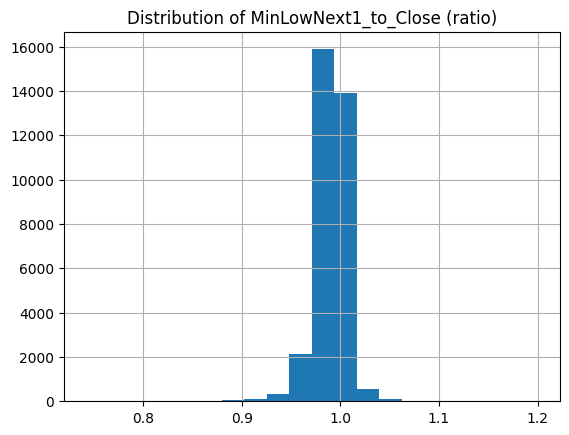

In [168]:
result.Ratio_MinLowNext1_to_Close.hist(bins=20)
plt.title(f'Distribution of MinLowNext1_to_Close (ratio)')
# Show the plot
plt.show()

In [169]:
result.Ratio_MinLowNext1_to_Close.describe().T

,Ratio_MinLowNext1_to_Close
count,33130.000000
mean,0.990387
std,0.015716
min,0.742412
25%,0.984268
50%,0.992484
75%,0.998531
max,1.199653


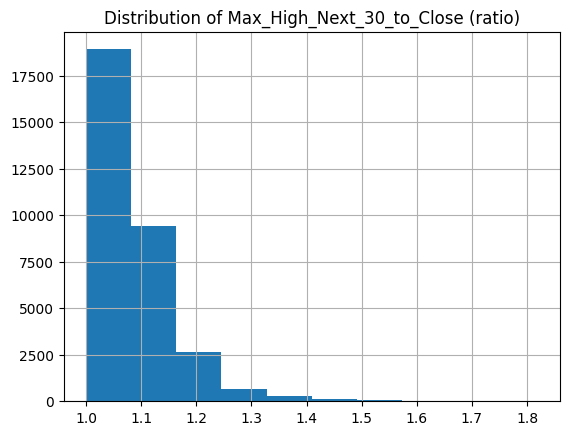

In [170]:
result.Ratio_MaxHighNext30_to_Close.hist()
plt.title(f'Distribution of Max_High_Next_30_to_Close (ratio)')
# Show the plot
plt.show()

In [171]:
result.Ratio_MaxHighNext30_to_Close.describe().T

,Ratio_MaxHighNext30_to_Close
count,32206.000000
mean,1.086332
std,0.077778
min,1.000000
25%,1.032850
50%,1.067475
75%,1.115245
max,1.818182


In [172]:
result[result.Ratio_MaxHighNext30_to_Close>=1.3].sample(5)

,Date,High,Low,Close_x,Ticker,Max_High_Next_30,Min_Low_Next_30,Min_Low_Next_1,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close
22490,2024-04-19,84.084239,75.391032,75.983337,NVDA,115.489707,75.391032,76.182763,1.519935,0.992205,1.002625
22129,2022-11-09,14.160023,13.709643,13.726583,NVDA,18.727388,13.709643,14.494818,1.364315,0.998766,1.055967
4432,2024-05-08,130.905619,126.070198,129.678665,AVGO,181.168721,126.070198,127.392040,1.397059,0.972174,0.982367
8930,2026-03-26,286.156905,278.701209,280.389099,GOOG,396.858363,271.195610,273.138198,1.415384,0.967212,0.974140
16392,2024-01-12,400.318410,395.063633,396.162354,LICI.NS,561.305715,395.063633,396.162354,1.416858,0.997227,1.000000


In [173]:
# ~2.2% cases TAKE PROFIT (30%)
len(result[result.Ratio_MaxHighNext30_to_Close>=1.3])/len(result)

0.022102946054337665

<Axes: >

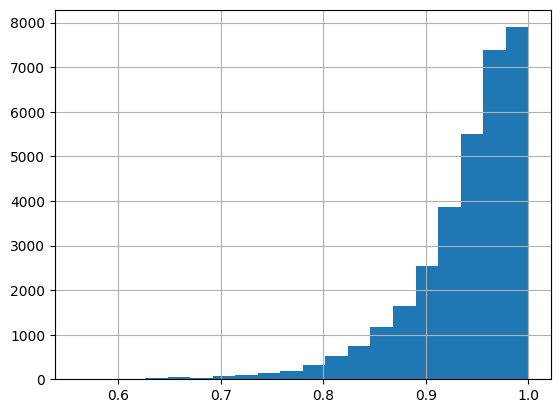

In [174]:
# High intra-day volatility, especially on earlier days after the IPO
result.Ratio_MinLowNext30_to_Close.hist(bins=20)

In [175]:
result.Ratio_MinLowNext30_to_Close.describe().T

,Ratio_MinLowNext30_to_Close
count,32206.000000
mean,0.937932
std,0.054507
min,0.560331
25%,0.915349
50%,0.952998
75%,0.977620
max,1.000000


In [176]:
result[result.Ratio_MinLowNext30_to_Close<=0.8].sample(5)

,Date,High,Low,Close_x,Ticker,Max_High_Next_30,Min_Low_Next_30,Min_Low_Next_1,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close
2024,2022-10-06,121.529999,119.500000,120.300003,AMZN,121.529999,85.870003,113.879997,1.010224,0.713799,0.946633
17767,2025-07-16,789.317359,765.639023,783.130066,LLY,813.293054,618.512009,753.601488,1.038516,0.789795,0.962294
9917,2026-03-02,31.820000,31.040001,31.559999,HDB,31.820000,23.910000,30.450001,1.008238,0.757605,0.964829
23860,2025-10-03,57.242358,55.670815,56.794708,NVO,58.004320,43.003201,56.813755,1.021298,0.757169,1.000335
17689,2025-03-24,857.790830,828.985728,855.841492,LLY,893.047597,669.998438,839.039378,1.043473,0.782853,0.980368


In [177]:
# ~2.7% cases STOP LOSS (-20%)
len(result[result.Ratio_MinLowNext30_to_Close<=0.8])/len(result)

0.027138678647890723

In [178]:
# Merge the results back with the original dataframe
new_df = new_df.merge(result[['Date', 'Ticker', 'Max_High_Next_30', 'Min_Low_Next_30','Ratio_MaxHighNext30_to_Close','Ratio_MinLowNext30_to_Close','Ratio_MinLowNext1_to_Close']], on=['Date', 'Ticker'])

In [179]:
new_df.sample(5)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,sim1_gross_rev_pred11,sim1_fees_pred11,sim1_net_rev_pred11,pred9_rank,pred10_rank,Max_High_Next_30,Min_Low_Next_30,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close
2385,176.639999,177.929993,173.899994,174.419998,72147400.0,0.0,0.0,AMZN,2024,March,...,0.0,0.0,0.0,3.0,17.0,189.770004,166.320007,1.088006,0.953560,0.999197
6367,390.290009,393.929993,390.000000,393.739990,2573400.0,0.0,0.0,BRK-B,2024,February,...,0.0,0.0,0.0,7.0,20.0,430.000000,390.000000,1.092091,0.990501,1.001575
7170,760.773511,787.038860,760.773511,786.578064,7933.0,0.0,0.0,CDI.PA,2023,April,...,-0.0,0.0,0.0,26.0,25.0,803.627489,711.230347,1.021675,0.904208,1.002929
22803,170.920853,170.970734,164.177395,166.621399,193114300.0,0.0,0.0,NVDA,2025,July,...,0.0,0.0,0.0,8.0,10.0,184.028708,164.177395,1.104472,0.985332,1.005628
1372,364.067665,366.567680,356.834770,359.621063,1539400.0,0.0,0.0,ACN,2024,March,...,-0.0,0.0,0.0,17.0,15.0,369.764332,298.711700,1.028205,0.830629,1.002441


### 3.2.3) [Code Snippet 2] Generate fin.result for one date

In [180]:
from dataclasses import dataclass

@dataclass
class SimulationParams:
    initial_capital: float
    threshold: float
    fees: float
    top_k: int
    portfolio_optimization: bool
    stop_loss: float
    take_profit: float
    lower_entry: float

In [181]:
# Example of initializing with some values
sim_params = SimulationParams(
    initial_capital=10000,        # initial capital = $10k
    threshold=0.55,               # select all binary predictions with probability>=0.55
    fees=0.002,                   # trading fees = 0.2% (buy+sell)
    top_k=10,                     # select top_k predictions
    portfolio_optimization=False, # no portfolio optimizaiton
    stop_loss=0.8,                # automatic sell (with loss) if price (any of next 30 days) is lower than -20% from Close
    take_profit=1.3,              # automatic sell (with profit) if price (any of next 30 days) is higher than +30% from Close
    lower_entry= 0.995                # buy next day with the price = [Close] * 0.995 (try to buy cheaper)
)

print(sim_params)

SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=10, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.995)


In [182]:
# sorted array of dates for Simulation
DATES = new_df[new_df.split=='test'].sort_values(by='Date').Date.unique()
print(f' Min date {DATES.min()}, max date {DATES.max()}')

 Min date 2022-09-16 00:00:00, max date 2026-09-18 00:00:00


In [183]:
date = DATES[0]
date

Timestamp('2022-09-16 00:00:00')

In [184]:
# 1. get TOP_K predictions from pred10_rf_best_rule_55, that are higher than THE THRESHOLD
if sim_params.top_k is None:
  one_day_predictions_df = new_df[(new_df.Date==date)&(new_df.proba_pred10 > sim_params.threshold)]
else:
  one_day_predictions_df = new_df[(new_df.Date==date)&(new_df.proba_pred10 > sim_params.threshold)&(new_df.pred10_rank<=sim_params.top_k)]

In [185]:
one_day_predictions_df[['Date','Ticker',to_predict,'growth_future_30d','proba_pred10','pred10_rank']]

,Date,Ticker,is_positive_growth_30d_future,growth_future_30d,proba_pred10,pred10_rank
5025,2022-09-16,BHARTIARTL.NS,1,1.071699,0.617143,5.0
12056,2022-09-16,IDEXY,1,1.055013,0.626421,3.0
14066,2022-09-16,ITC.NS,1,1.054935,0.726549,1.0
17059,2022-09-16,LLY,1,1.165140,0.611808,6.0
19058,2022-09-16,MC.PA,1,1.015324,0.597044,7.0
23096,2022-09-16,NVO,1,1.074344,0.593200,10.0
26118,2022-09-16,RMS.PA,1,1.076233,0.595562,9.0
27141,2022-09-16,SAP,1,1.164046,0.626258,4.0
28146,2022-09-16,SBIN.NS,1,1.026878,0.665901,2.0
31153,2022-09-16,TTE,1,1.107068,0.596347,8.0


In [186]:
# 2. Get non-normalized weights: probability-threshold + 0.01
one_day_predictions_df['weight'] = one_day_predictions_df.proba_pred10 - sim_params.threshold +0.01

In [187]:
one_day_predictions_df[['Date','Ticker','Close_x', to_predict,'growth_future_30d','proba_pred10','pred10_rank','weight']]

,Date,Ticker,Close_x,is_positive_growth_30d_future,growth_future_30d,proba_pred10,pred10_rank,weight
5025,2022-09-16,BHARTIARTL.NS,755.872681,1,1.071699,0.617143,5.0,0.077143
12056,2022-09-16,IDEXY,4.979537,1,1.055013,0.626421,3.0,0.086421
14066,2022-09-16,ITC.NS,273.641022,1,1.054935,0.726549,1.0,0.186549
17059,2022-09-16,LLY,299.354401,1,1.165140,0.611808,6.0,0.071808
19058,2022-09-16,MC.PA,589.654724,1,1.015324,0.597044,7.0,0.057044
23096,2022-09-16,NVO,45.902225,1,1.074344,0.593200,10.0,0.053200
26118,2022-09-16,RMS.PA,1180.281494,1,1.076233,0.595562,9.0,0.055562
27141,2022-09-16,SAP,79.432671,1,1.164046,0.626258,4.0,0.086258
28146,2022-09-16,SBIN.NS,521.925049,1,1.026878,0.665901,2.0,0.125901
31153,2022-09-16,TTE,40.353031,1,1.107068,0.596347,8.0,0.056347


In [188]:
# 3. Get normalized weights
one_day_predictions_df['weight_norm'] = one_day_predictions_df['weight']/one_day_predictions_df['weight'].sum()

In [189]:
one_day_predictions_df[['Date','Ticker','Close_x', to_predict,'growth_future_30d','proba_pred10','pred10_rank','weight','weight_norm']]

,Date,Ticker,Close_x,is_positive_growth_30d_future,growth_future_30d,proba_pred10,pred10_rank,weight,weight_norm
5025,2022-09-16,BHARTIARTL.NS,755.872681,1,1.071699,0.617143,5.0,0.077143,0.090096
12056,2022-09-16,IDEXY,4.979537,1,1.055013,0.626421,3.0,0.086421,0.100931
14066,2022-09-16,ITC.NS,273.641022,1,1.054935,0.726549,1.0,0.186549,0.217872
17059,2022-09-16,LLY,299.354401,1,1.165140,0.611808,6.0,0.071808,0.083865
19058,2022-09-16,MC.PA,589.654724,1,1.015324,0.597044,7.0,0.057044,0.066622
23096,2022-09-16,NVO,45.902225,1,1.074344,0.593200,10.0,0.053200,0.062133
26118,2022-09-16,RMS.PA,1180.281494,1,1.076233,0.595562,9.0,0.055562,0.064891
27141,2022-09-16,SAP,79.432671,1,1.164046,0.626258,4.0,0.086258,0.100741
28146,2022-09-16,SBIN.NS,521.925049,1,1.026878,0.665901,2.0,0.125901,0.147040
31153,2022-09-16,TTE,40.353031,1,1.107068,0.596347,8.0,0.056347,0.065809


In [190]:
# 4. Capital: either 1/30 of initial (assuming you trade every day), or everything that you can sell from 30 days ago
one_day_predictions_df['investment'] = one_day_predictions_df['weight_norm'] * sim_params.initial_capital /30

In [191]:
# See the allocation of an 'investment' at a price = 'Adj.Close' * sim_params.lower_entry (e.g. 0.995 - try to buy cheaper)
one_day_predictions_df[['Date','Ticker','Close_x', to_predict,'growth_future_30d','proba_pred10','pred10_rank','weight','weight_norm', 'investment']]

,Date,Ticker,Close_x,is_positive_growth_30d_future,growth_future_30d,proba_pred10,pred10_rank,weight,weight_norm,investment
5025,2022-09-16,BHARTIARTL.NS,755.872681,1,1.071699,0.617143,5.0,0.077143,0.090096,30.031954
12056,2022-09-16,IDEXY,4.979537,1,1.055013,0.626421,3.0,0.086421,0.100931,33.643779
14066,2022-09-16,ITC.NS,273.641022,1,1.054935,0.726549,1.0,0.186549,0.217872,72.624068
17059,2022-09-16,LLY,299.354401,1,1.165140,0.611808,6.0,0.071808,0.083865,27.954878
19058,2022-09-16,MC.PA,589.654724,1,1.015324,0.597044,7.0,0.057044,0.066622,22.207273
23096,2022-09-16,NVO,45.902225,1,1.074344,0.593200,10.0,0.053200,0.062133,20.711027
26118,2022-09-16,RMS.PA,1180.281494,1,1.076233,0.595562,9.0,0.055562,0.064891,21.630281
27141,2022-09-16,SAP,79.432671,1,1.164046,0.626258,4.0,0.086258,0.100741,33.580438
28146,2022-09-16,SBIN.NS,521.925049,1,1.026878,0.665901,2.0,0.125901,0.147040,49.013464
31153,2022-09-16,TTE,40.353031,1,1.107068,0.596347,8.0,0.056347,0.065809,21.936173


In [192]:
# 5. Lower Entry: the trade is executed only is Low price for next day is lower than bet
one_day_predictions_df['lower_entry'] = (one_day_predictions_df['Ratio_MinLowNext1_to_Close']<=sim_params.lower_entry).astype(int)

In [193]:
one_day_predictions_df.tail(10)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,pred10_rank,Max_High_Next_30,Min_Low_Next_30,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry
5025,763.968003,763.968003,752.770261,755.872681,20211162.0,0.0,0.0,BHARTIARTL.NS,2022,September,...,5.0,808.371314,730.229393,1.069454,0.966075,0.990444,0.077143,0.090096,30.031954,1
12056,4.904424,4.992792,4.886751,4.979537,1318000.0,0.0,0.0,IDEXY,2022,September,...,3.0,5.302081,4.405145,1.064774,0.884650,0.989352,0.086421,0.100931,33.643779,1
14066,274.508270,276.366688,272.319470,273.641022,12973988.0,0.0,0.0,ITC.NS,2022,September,...,1.0,291.729600,266.992088,1.066103,0.975702,0.993360,0.186549,0.217872,72.624068,1
17059,298.462789,302.329605,297.270749,299.354401,4380200.0,0.0,0.0,LLY,2022,September,...,6.0,350.320957,287.172481,1.170255,0.959306,0.963612,0.071808,0.083865,27.954878,1
19058,584.583417,591.775441,580.987377,589.654724,1069261.0,0.0,0.0,MC.PA,2022,September,...,7.0,611.876148,548.346653,1.037685,0.929945,0.981861,0.057044,0.066622,22.207273,1
23096,45.888648,46.142101,45.259541,45.902225,2869800.0,0.0,0.0,NVO,2022,September,...,10.0,49.459612,43.005615,1.077499,0.936896,0.982449,0.053200,0.062133,20.711027,1
26118,1189.904662,1189.904662,1161.997476,1180.281494,187626.0,0.0,0.0,RMS.PA,2022,September,...,9.0,1322.222910,1116.768376,1.120261,0.946188,0.988993,0.055562,0.064891,21.630281,1
27141,78.543144,79.612463,78.448515,79.432671,1093200.0,0.0,0.0,SAP,2022,September,...,4.0,93.816470,74.019812,1.181082,0.931856,0.984989,0.086258,0.100741,33.580438,1
28146,528.706905,533.259139,520.531514,521.925049,14739280.0,0.0,0.0,SBIN.NS,2022,September,...,2.0,544.593254,479.515179,1.043432,0.918743,0.995995,0.125901,0.147040,49.013464,0
31153,39.878384,40.385211,39.637039,40.353031,1817100.0,0.0,0.0,TTE,2022,September,...,8.0,44.689876,36.386490,1.107473,0.901704,0.964364,0.056347,0.065809,21.936173,1


In [194]:
# 6. Stop Loss: happens if the current price (or Low price) goes below stop loss threshold during one of the next 5 periods (1 week)
one_day_predictions_df['stop_loss'] = (one_day_predictions_df['Ratio_MinLowNext30_to_Close'] <= sim_params.stop_loss).astype(int)

In [195]:
# 7. Take Profit: take the money if the current Price (or Max_price) goes higher than sim_params.take_profit
one_day_predictions_df['take_profit'] = (one_day_predictions_df['Ratio_MaxHighNext30_to_Close'] >= sim_params.take_profit).astype(int)

In [196]:
one_day_predictions_df.tail(10)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Min_Low_Next_30,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit
5025,763.968003,763.968003,752.770261,755.872681,20211162.0,0.0,0.0,BHARTIARTL.NS,2022,September,...,730.229393,1.069454,0.966075,0.990444,0.077143,0.090096,30.031954,1,0,0
12056,4.904424,4.992792,4.886751,4.979537,1318000.0,0.0,0.0,IDEXY,2022,September,...,4.405145,1.064774,0.884650,0.989352,0.086421,0.100931,33.643779,1,0,0
14066,274.508270,276.366688,272.319470,273.641022,12973988.0,0.0,0.0,ITC.NS,2022,September,...,266.992088,1.066103,0.975702,0.993360,0.186549,0.217872,72.624068,1,0,0
17059,298.462789,302.329605,297.270749,299.354401,4380200.0,0.0,0.0,LLY,2022,September,...,287.172481,1.170255,0.959306,0.963612,0.071808,0.083865,27.954878,1,0,0
19058,584.583417,591.775441,580.987377,589.654724,1069261.0,0.0,0.0,MC.PA,2022,September,...,548.346653,1.037685,0.929945,0.981861,0.057044,0.066622,22.207273,1,0,0
23096,45.888648,46.142101,45.259541,45.902225,2869800.0,0.0,0.0,NVO,2022,September,...,43.005615,1.077499,0.936896,0.982449,0.053200,0.062133,20.711027,1,0,0
26118,1189.904662,1189.904662,1161.997476,1180.281494,187626.0,0.0,0.0,RMS.PA,2022,September,...,1116.768376,1.120261,0.946188,0.988993,0.055562,0.064891,21.630281,1,0,0
27141,78.543144,79.612463,78.448515,79.432671,1093200.0,0.0,0.0,SAP,2022,September,...,74.019812,1.181082,0.931856,0.984989,0.086258,0.100741,33.580438,1,0,0
28146,528.706905,533.259139,520.531514,521.925049,14739280.0,0.0,0.0,SBIN.NS,2022,September,...,479.515179,1.043432,0.918743,0.995995,0.125901,0.147040,49.013464,0,0,0
31153,39.878384,40.385211,39.637039,40.353031,1817100.0,0.0,0.0,TTE,2022,September,...,36.386490,1.107473,0.901704,0.964364,0.056347,0.065809,21.936173,1,0,0


In [197]:
# future_gross_return, depending on lower_entry, take_profit, stop_loss

import random

def get_future_gross_return(row, sim_params:SimulationParams):
  if row['lower_entry']==0: # no trade, investment is untouched, no fees
    return row['investment']

  # buy trade is filled for ALL next cases:
  if row['take_profit']==1 and row['stop_loss']==1:
    if random.random()>0.5: #assume take_profit event was first
      return  row['investment']*(sim_params.take_profit+(1-sim_params.lower_entry))
    else: #assume stop_loss event was first
      return row['investment']*(sim_params.stop_loss+(1-sim_params.lower_entry))

  if row['take_profit']==1: # take some good profit, pay fees
    return  row['investment']*(sim_params.take_profit+(1-sim_params.lower_entry))

  if row['stop_loss']==1: # fix the loss, pay fees
      return row['investment']*(sim_params.stop_loss+(1-sim_params.lower_entry))

  # no stop_loss and no take_profit
  if pd.isna(row['growth_future_30d']):
    return row['investment'] # no information on growth in 30 days --> return the same investment in 5 days
  else:
    return row['investment']*(row['growth_future_30d']+(1-sim_params.lower_entry))

In [198]:
# fees, depending on lower_entry, take_profit, stop_loss

def get_fees(row, sim_params:SimulationParams):
  if row['lower_entry']==0: # no trade ==> no fees
    return 0

  # pay fees in all other cases
  return -row['investment']*sim_params.fees


In [199]:
# 8. calculate future returns (when the order is executed + stop_loss True/False + take_profit True/False)
one_day_predictions_df['future_gross_return'] = one_day_predictions_df.apply(lambda row: get_future_gross_return(row,sim_params=sim_params), axis=1)
one_day_predictions_df['fees'] =  one_day_predictions_df.apply(lambda row: get_fees(row,sim_params=sim_params), axis=1)
one_day_predictions_df['future_net_return'] = one_day_predictions_df['future_gross_return'] + one_day_predictions_df['fees']

# OLD code when no stop_loss, take_profit, and if order executed
# one_day_predictions_df['investment'] * one_day_predictions_df['growth_future_5d']
# one_day_predictions_df['fees'] =   - one_day_predictions_df['investment'] * sim_params.fees


In [200]:
# result
one_day_predictions_df

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
5025,763.968003,763.968003,752.770261,755.872681,20211162.0,0.0,0.0,BHARTIARTL.NS,2022,September,...,0.990444,0.077143,0.090096,30.031954,1,0,0,32.335370,-0.060064,32.275306
12056,4.904424,4.992792,4.886751,4.979537,1318000.0,0.0,0.0,IDEXY,2022,September,...,0.989352,0.086421,0.100931,33.643779,1,0,0,35.662858,-0.067288,35.595571
14066,274.508270,276.366688,272.319470,273.641022,12973988.0,0.0,0.0,ITC.NS,2022,September,...,0.993360,0.186549,0.217872,72.624068,1,0,0,76.976808,-0.145248,76.831559
17059,298.462789,302.329605,297.270749,299.354401,4380200.0,0.0,0.0,LLY,2022,September,...,0.963612,0.071808,0.083865,27.954878,1,0,0,32.711116,-0.055910,32.655206
19058,584.583417,591.775441,580.987377,589.654724,1069261.0,0.0,0.0,MC.PA,2022,September,...,0.981861,0.057044,0.066622,22.207273,1,0,0,22.658623,-0.044415,22.614209
23096,45.888648,46.142101,45.259541,45.902225,2869800.0,0.0,0.0,NVO,2022,September,...,0.982449,0.053200,0.062133,20.711027,1,0,0,22.354328,-0.041422,22.312906
26118,1189.904662,1189.904662,1161.997476,1180.281494,187626.0,0.0,0.0,RMS.PA,2022,September,...,0.988993,0.055562,0.064891,21.630281,1,0,0,23.387372,-0.043261,23.344111
27141,78.543144,79.612463,78.448515,79.432671,1093200.0,0.0,0.0,SAP,2022,September,...,0.984989,0.086258,0.100741,33.580438,1,0,0,39.257066,-0.067161,39.189905
28146,528.706905,533.259139,520.531514,521.925049,14739280.0,0.0,0.0,SBIN.NS,2022,September,...,0.995995,0.125901,0.147040,49.013464,0,0,0,49.013464,0.000000,49.013464
31153,39.878384,40.385211,39.637039,40.353031,1817100.0,0.0,0.0,TTE,2022,September,...,0.964364,0.056347,0.065809,21.936173,1,0,0,24.394522,-0.043872,24.350650


### 3.2.4 [Code Snippet 3] Wrap up one day simulation into a function

In [201]:
# Simulation Parameters
sim_params = SimulationParams(
    initial_capital=10000,                 # initial capital = $10k
    threshold=0.55,                        # select all binary predictions with probability>=0.55
    fees=0.002,                            # trading fees = 0.2% (buy+sell)
    top_k=10,                              # select top_k predictions
    portfolio_optimization=False,          # no portfolio optimizaiton
    stop_loss=0.8,                         # automatic sell (with loss) if price (any of next 30 trading days) is lower than -20% from Close
    take_profit=1.3,                       # automatic sell (with profit) if price (any of next 30 trading days) is higher than +30% from Close
    lower_entry= 0.995                     # buy next day with the price = [Close] * 0.995 (try to buy cheaper)
)

In [202]:
def one_date_simulation(date:str, invest_sum:float, df:pd.DataFrame, sim_params:SimulationParams, predictor:str='proba_pred10'):

  rank_column = predictor.split('_')[1]+'_rank' # e.g. 'proba_pred10' --> 'pred10_rank'
  # 1. get TOP_K (or ALL) predictions from the predictor (pred14_rf_best_rule_53 by default), that are higher than THE THRESHOLD
  if sim_params.top_k is None:
    one_day_predictions_df = df[(df.Date==date)&(df[predictor] > sim_params.threshold)]
  else:
    one_day_predictions_df = df[(df.Date==date)&(df[predictor] > sim_params.threshold)&(df[rank_column]<=sim_params.top_k)]

  FIELDS = ['Close_x', 'Ticker', 'Date', predictor, rank_column, 'growth_future_30d', 'Ratio_MaxHighNext30_to_Close','Ratio_MinLowNext30_to_Close','Ratio_MinLowNext1_to_Close']
  result_df = one_day_predictions_df[FIELDS].copy()

  # 2. Get non-normalized weights: probability-threshold + 0.01
  result_df['weight'] = result_df[predictor] - sim_params.threshold +0.01

  # 3. Get normalized weights
  result_df['weight_norm'] = result_df['weight']/result_df['weight'].sum()

  # 4. Make bets to allocate 'invest_sum' across all suitable predictions
  result_df['investment'] = result_df['weight_norm'] * invest_sum

  # 5. Lower Entry: the trade is executed only is Low price for next day is lower than the bet (Adj_Close_today * sim_params.lower_entry)
    # [ONLY TRADES with lower_entry==1 are filled by the exchange]
  result_df['lower_entry'] = (result_df['Ratio_MinLowNext1_to_Close'] <= sim_params.lower_entry).astype(int)

  # 6. Stop Loss: happens if the current price (or Low price) goes below stop loss threshold during one of the next 5 periods (1 week)
  result_df['stop_loss'] = (result_df['Ratio_MinLowNext30_to_Close'] <= sim_params.stop_loss).astype(int)

  # 7. Take Profit: take the money if the current Price (or Max_price) goes higher than sim_params.take_profit
  result_df['take_profit'] = (result_df['Ratio_MaxHighNext30_to_Close'] >= sim_params.take_profit).astype(int)

  # 8. Calculate future returns (when the order is executed + stop_loss True/False + take_profit True/False)
  result_df['future_gross_return'] = result_df.apply(lambda row: get_future_gross_return(row,sim_params=sim_params), axis=1)
  result_df['fees'] =  result_df.apply(lambda row: get_fees(row,sim_params=sim_params), axis=1)
  result_df['future_net_return'] = result_df['future_gross_return'] + result_df['fees']

  return result_df

In [203]:
predictor = 'proba_pred10'
rank = predictor.split('_')[1]+'_rank'
print(rank)

pred10_rank


In [204]:
r = one_date_simulation(date='2022-09-29', invest_sum=sim_params.initial_capital/30, df=new_df, sim_params=sim_params, predictor='proba_pred10')

In [205]:
r

,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
7033,539.526062,CDI.PA,2022-09-29,0.628330,8.0,1.145038,1.107719,0.983036,0.988126,0.088330,0.084000,27.999842,1,0,0,32.200888,-0.056000,32.144888
9061,27.182081,HDB,2022-09-29,0.632432,7.0,1.173087,1.144943,0.971328,1.013193,0.092432,0.087900,29.299941,0,0,0,29.299941,0.000000,29.299941
12065,4.475840,IDEXY,2022-09-29,0.661652,2.0,1.273508,1.234246,0.986180,1.003948,0.121652,0.115687,38.562410,0,0,0,38.562410,0.000000,38.562410
13070,15.004029,INFY,2022-09-29,0.684365,1.0,1.148452,1.149649,0.988166,1.004142,0.144365,0.137286,45.762150,0,0,0,45.762150,0.000000,45.762150
19067,560.609985,MC.PA,2022-09-29,0.626980,9.0,1.129605,1.104934,0.978125,0.983553,0.086980,0.082715,27.571738,1,0,0,31.283037,-0.055143,31.227894
22100,12.176166,NVDA,2022-09-29,0.623988,10.0,1.288871,1.218576,0.884861,0.988134,0.083988,0.079870,26.623205,1,0,0,34.446984,-0.053246,34.393737
24110,302.501648,OR.PA,2022-09-29,0.636190,6.0,1.047008,1.054894,0.929952,0.995052,0.096190,0.091474,30.491361,0,0,0,30.491361,0.000000,30.491361
27150,76.158463,SAP,2022-09-29,0.653946,4.0,1.331759,1.233350,0.983971,1.008822,0.113946,0.108360,36.119872,0,0,0,36.119872,0.000000,36.119872
29149,88.812172,SIE.DE,2022-09-29,0.655589,3.0,1.228374,1.196825,0.985447,1.006717,0.115589,0.109922,36.640664,0,0,0,36.640664,0.000000,36.640664
31162,38.050430,TTE,2022-09-29,0.648086,5.0,1.225295,1.251447,0.972562,0.996141,0.108086,0.102786,34.262150,0,0,0,34.262150,0.000000,34.262150


In [206]:
# initial investment
r.investment.sum()

np.float64(333.3333333333333)

In [207]:
# result in 30 days (returns+fees)
r.future_net_return.sum()

np.float64(348.9050671855094)

### 3.2.5 [Code snippet 4] Generate fin result for ALL days

In [208]:
all_dates = new_df[new_df.split=='test'].sort_values(by='Date').Date.unique()
all_dates

<DatetimeArray>
['2022-09-16 00:00:00', '2022-09-19 00:00:00', '2022-09-20 00:00:00',
 '2022-09-21 00:00:00', '2022-09-22 00:00:00', '2022-09-23 00:00:00',
 '2022-09-26 00:00:00', '2022-09-27 00:00:00', '2022-09-28 00:00:00',
 '2022-09-29 00:00:00',
 ...
 '2026-09-07 00:00:00', '2026-09-08 00:00:00', '2026-09-09 00:00:00',
 '2026-09-10 00:00:00', '2026-09-11 00:00:00', '2026-09-14 00:00:00',
 '2026-09-15 00:00:00', '2026-09-16 00:00:00', '2026-09-17 00:00:00',
 '2026-09-18 00:00:00']
Length: 1040, dtype: datetime64[ns]

In [209]:
# simulate for all dates but last 5
all_dates[0:-5]

<DatetimeArray>
['2022-09-16 00:00:00', '2022-09-19 00:00:00', '2022-09-20 00:00:00',
 '2022-09-21 00:00:00', '2022-09-22 00:00:00', '2022-09-23 00:00:00',
 '2022-09-26 00:00:00', '2022-09-27 00:00:00', '2022-09-28 00:00:00',
 '2022-09-29 00:00:00',
 ...
 '2026-08-31 00:00:00', '2026-09-01 00:00:00', '2026-09-02 00:00:00',
 '2026-09-03 00:00:00', '2026-09-04 00:00:00', '2026-09-07 00:00:00',
 '2026-09-08 00:00:00', '2026-09-09 00:00:00', '2026-09-10 00:00:00',
 '2026-09-11 00:00:00']
Length: 1035, dtype: datetime64[ns]

In [210]:
# these last days we only "sell" the positions
all_dates[-5:]

<DatetimeArray>
['2026-09-14 00:00:00', '2026-09-15 00:00:00', '2026-09-16 00:00:00',
 '2026-09-17 00:00:00', '2026-09-18 00:00:00']
Length: 5, dtype: datetime64[ns]

In [211]:
capital= 5 * [sim_params.initial_capital/5]
capital[-5]

2000.0

In [212]:
def simulate(df:pd.DataFrame, sim_params:SimulationParams):

  simulation_df = None

  # all dates for simulation
  all_dates = df[df.split=='test'].sort_values(by='Date').Date.unique()

  # arrays of dates and capital available (capital for the first 5 days)
  dates = []
  capital= 30 * [sim_params.initial_capital/30]  # first 30 periods trade with 1/30 of the initial_capital. e.g. [333,...,333] = 10k in total

  for current_date in all_dates[0:-30]:  #growth_future_30d is not defined for the last 30 days : ALL, but last 30 dates

    current_invest_sum = capital[-30]    # take the value or everything that you can sell from 30 days ago

    one_day_simulation_results = one_date_simulation(date = current_date,  # one day simulation result
                                    invest_sum = current_invest_sum,
                                    df = df,
                                    sim_params=sim_params,
                                    # predictor='proba_pred7')
                                    predictor='proba_pred10')

    # add capital available in 30 days
    if len(one_day_simulation_results)==0:  #no predictions -> no trades
      capital.append(current_invest_sum)
    else:
      capital.append(one_day_simulation_results.future_net_return.sum())
    dates.append(current_date)

    if simulation_df is None:
      simulation_df = one_day_simulation_results
    else:
      simulation_df = pd.concat([simulation_df, one_day_simulation_results], ignore_index=True)

  # add last 5 days to make the count of data points equal for dates/capital arrays
  dates.extend(all_dates[-30:])
  capital_df = pd.DataFrame({'capital':capital}, index=pd.to_datetime(dates))

  # results:
  print(f'============================================================================================')
  print(f'SIMULATION STARTED')
  print(f'Simulations params: {sim_params}')
  print(f' Count bids {len(simulation_df)} in total, avg.bids per day {len(simulation_df)/simulation_df.Date.nunique()},  filled bids {len(simulation_df[simulation_df.lower_entry==1])}, fill bids percent = {len(simulation_df[simulation_df.lower_entry==1])/len(simulation_df)}')
  stop_loss_filter = (simulation_df.lower_entry==1)&(simulation_df.stop_loss==1)
  print(f'  Stop loss events: count = {len(simulation_df[stop_loss_filter])}, net loss = {simulation_df[stop_loss_filter].future_net_return.sum()-simulation_df[stop_loss_filter].investment.sum()} ')
  take_profit_filter = (simulation_df.lower_entry==1)&(simulation_df.take_profit==1)
  print(f'  Take profit events: count = {len(simulation_df[take_profit_filter])}, net profit = {simulation_df[take_profit_filter].future_net_return.sum()-simulation_df[take_profit_filter].investment.sum()} ')
  print(f'  Start capital = {sim_params.initial_capital}, Resulting capital: {capital_df[-30:].capital.sum()} ')
  print(f'  CAGR in 4 years: {np.round((capital_df[-30:].capital.sum()/sim_params.initial_capital)**(1/4),3)} or {np.round(((capital_df[-30:].capital.sum()/sim_params.initial_capital)**(1/4)-1)*100.0,2)} % of avg. growth per year')
  print(f'============================================================================================')
  return simulation_df,capital_df

In [213]:
# One initial simulation
sim_params = SimulationParams(
    initial_capital = 10000,        # initial capital = $10k
    threshold = 0.55,               # select all binary predictions with probability>=0.55
    fees = 0.002,                   # trading fees = 0.2% (buy+sell)
    top_k = 5,                      # select top_k=5 predictions
    portfolio_optimization = False, # no portfolio optimization
    stop_loss = 0.8,                # automatic sell (with loss) if price (any of next 5 days) is lower than -20% from Adj.Close
    take_profit = 1.3,              # automatic sell (with profit) if price (any of next 5 days) is higher than +30% from Adj.Close
    lower_entry = 0.99               # buy next day with the price = [Close] * 0.99 (try to buy cheaper)
)

res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 1051, fill bids percent = 0.4293300653594771
  Stop loss events: count = 44, net loss = -882.7639989945797 
  Take profit events: count = 18, net profit = 435.11845198548235 
  Start capital = 10000, Resulting capital: 11726.788879522464 
  CAGR in 4 years: 1.041 or 4.06 % of avg. growth per year


### 3.2.5 [Code Snippet 5] Find optimal parameters of simulation

In [214]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# iterate over lower_entry
for lower_entry in [0.97,0.98,0.99,1,1.01,1.02,1.03]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = 0.55,               # select all binary predictions with probability>=0.55
      fees = 0.002,                   # trading fees = 0.2% (buy+sell)
      top_k = 5,                     # select top_k predictions
      portfolio_optimization = False, # no portfolio optimization
      stop_loss = 0.8,                # automatic sell (with loss) if price (any of next 5 days) is lower than -5% from Adj.Close
      take_profit = 1.3,              # automatic sell (with profit) if price (any of next 5 days) is higher than +20% from Adj.Close
      lower_entry = lower_entry                # buy next day with the price = [Adj.Close] * 0.995 (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.97)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 194, fill bids percent = 0.07924836601307189
  Stop loss events: count = 23, net loss = -384.6850429879528 
  Take profit events: count = 7, net profit = 146.32642517955094 
  Start capital = 10000, Resulting capital: 10192.752468849263 
  CAGR in 4 years: 1.005 or 0.48 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.98)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 443, fill bids percent = 0.1809640522875817
  Stop loss events: count = 36, net loss = -626.9053827549378 
  Take profit events: count = 13, net profit = 324.5

In [215]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# (lower_entry=1.0) BEST PREVIOUS is CAGR 5.2%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=1.0)

# iterate over take profit   ==> new best take_profit=1.35
for take_profit in [1.2,1.25,1.3,1.35,1.4,1.45,1.5]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = 0.55,               # select all binary predictions with probability>=0.55
      fees = 0.002,                   # trading fees = 0.2% (buy+sell)
      top_k = 5,                     # select top_k predictions
      portfolio_optimization = False, # no portfolio optimization
      stop_loss = 0.8,                # automatic sell (with loss) if price (any of next 30 days) is lower than -5% from Adj.Close
      take_profit = take_profit,        # automatic sell (with profit) if price (any of next 30 days) is higher than +20% from Adj.Close
      lower_entry = 1                # buy next day with the price = [Close] * lower_entry (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.2, lower_entry=1)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 1961, fill bids percent = 0.801062091503268
  Stop loss events: count = 58, net loss = -1395.1511550076457 
  Take profit events: count = 118, net profit = 2092.512171341068 
  Start capital = 10000, Resulting capital: 12239.55315093972 
  CAGR in 4 years: 1.052 or 5.18 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.25, lower_entry=1)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 1961, fill bids percent = 0.801062091503268
  Stop loss events: count = 58, net loss = -1390.5194159442362 
  Take profit events: count = 47, net profit = 887.34484

In [216]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# (lower_entry=1.0) BEST PREVIOUS is CAGR 5.2%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=1.0)
# (take_profit=1.35) BEST PREVIOUS is CAGR 5.34%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.35, lower_entry=1.0)


# iterate over stop_loss
for stop_loss in [0.55,0.6,0.65,0.7,0.75,0.8]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = 0.55,               # select all binary predictions with probability>=0.55
      fees = 0.002,                   # trading fees = 0.2% (buy+sell)
      top_k = 5,                     # select top_k predictions
      portfolio_optimization = False, # no portfolio optimization
      stop_loss = stop_loss,                # automatic sell (with loss) if price (any of next 30 days) is lower than -"stop_loss"% from Close
      take_profit = 1.35,              # automatic sell (with profit) if price (any of next 30 days) is higher than +50% from Close
      lower_entry = 1                # buy next day with the price = [Close] * 1 (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.55, take_profit=1.35, lower_entry=1)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 1961, fill bids percent = 0.801062091503268
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 19, net profit = 508.81480160605247 
  Start capital = 10000, Resulting capital: 12961.933744487034 
  CAGR in 4 years: 1.067 or 6.7 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.55, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 2448 in total, avg.bids per day 3.438202247191011,  filled bids 1961, fill bids percent = 0.801062091503268
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 19, net profit = 508.81480160605247 
  Start capital = 100

In [217]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# (lower_entry=1.0) BEST PREVIOUS is CAGR 5.2%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=1.0)
# (take_profit=1.35) BEST PREVIOUS is CAGR 5.34%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.35, lower_entry=1.0)
# (stop_loss=0.6) BEST PREVIOUS is CAGR 6.7%  (top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)


for threshold in [0.51,0.52,0.53,0.54,0.55,0.56,0.57]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = threshold,               # select all binary predictions with probability>=threshold (iter param)
      fees = 0.002,                   # trading fees = 0.2% (buy+sell)
      top_k = 5,                     # select top_k predictions
      portfolio_optimization = False, # no portfolio optimization
      stop_loss = 0.6,                # automatic sell (with loss) if price (any of next 30 days) is lower than -40% from Close
      take_profit = 1.35,              # automatic sell (with profit) if price (any of next 30 days) is higher than +50% from Adj.Close
      lower_entry = 1                # buy next day with the price = [Close] * lower_entry (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.51, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 4068 in total, avg.bids per day 4.3789020452099034,  filled bids 3283, fill bids percent = 0.8070304818092429
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 31, net profit = 942.0810984731584 
  Start capital = 10000, Resulting capital: 12724.541315316435 
  CAGR in 4 years: 1.062 or 6.21 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.52, fees=0.002, top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 3734 in total, avg.bids per day 4.162764771460424,  filled bids 3003, fill bids percent = 0.8042313872522764
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 25, net profit = 644.8343720079001 
  Start capital = 10

In [218]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# (lower_entry=1.0) BEST PREVIOUS is CAGR 5.2%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=1.0)
# (take_profit=1.35) BEST PREVIOUS is CAGR 5.34%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.35, lower_entry=1.0)
# (stop_loss=0.6) BEST PREVIOUS is CAGR 6.7%  (top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
# (threshold=0.54) BEST PREVIOUS is CAGR 6.8%  (top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)


# iterate over top_k
for top_k in [1,2,3,4,5,6,8,10,20,33]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = 0.54,               # select all binary predictions with probability>=0.56
      fees = 0.002,                     # trading fees = 0.2% (buy+sell)
      top_k = top_k,                    # select top_k predictions
      portfolio_optimization = False,   # no portfolio optimization
      stop_loss = 0.6,                 # automatic sell (with loss) if price (any of next 30 days) is lower than
      take_profit = 1.35,              # automatic sell (with profit) if price (any of next 30 days) is higher than +50% from Close
      lower_entry = 1.0                # buy next day with the price = [Close] * (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=1, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
 Count bids 787 in total, avg.bids per day 1.0,  filled bids 626, fill bids percent = 0.795425667090216
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 4, net profit = 466.7172829358433 
  Start capital = 10000, Resulting capital: 12958.483547697651 
  CAGR in 4 years: 1.067 or 6.69 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=2, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
 Count bids 1449 in total, avg.bids per day 1.841168996188056,  filled bids 1159, fill bids percent = 0.7998619737750172
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 9, net profit = 604.4303289958573 
  Start capital = 10000, Resulting c

In [219]:
# BEST PREVIOUS CAGR is 4.1%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=0.99)
# (lower_entry=1.0) BEST PREVIOUS is CAGR 5.2%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.3, lower_entry=1.0)
# (take_profit=1.35) BEST PREVIOUS is CAGR 5.34%  (top_k=5, portfolio_optimization=False, stop_loss=0.8, take_profit=1.35, lower_entry=1.0)
# (stop_loss=0.6) BEST PREVIOUS is CAGR 6.7%  (top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
# (threshold=0.54) BEST PREVIOUS is CAGR 6.8%  (top_k=5, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
# (top_k=33) BEST PREVIOUS is CAGR 7.84%  (top_k=33, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)


# iterate over stop_loss
for stop_loss in [0.6, 0.65, 0.7,0.75, 0.8, 0.85]:
  # One simulation
  sim_params = SimulationParams(
      initial_capital = 10000,        # initial capital = $10k
      threshold = 0.54,               # select all binary predictions with probability>=0.56
      fees = 0.002,                   # trading fees = 0.2% (buy+sell)
      top_k = 33,                      # select top_k predictions
      portfolio_optimization = False, # no portfolio optimization
      stop_loss = stop_loss,                # automatic sell (with loss) if price (any of next 5 days) is lower than -5% from Adj.Close
      take_profit = 1.35,              # automatic sell (with profit) if price (any of next 5 days) is higher than +20% from Adj.Close
      lower_entry = 1                # buy next day with the price = [Adj.Close] * 0.995 (try to buy cheaper)
  )

  res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=33, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 6312 in total, avg.bids per day 8.02033036848793,  filled bids 5028, fill bids percent = 0.7965779467680608
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 75, net profit = 752.6394606696886 
  Start capital = 10000, Resulting capital: 13525.74176104472 
  CAGR in 4 years: 1.078 or 7.84 % of avg. growth per year
SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=33, portfolio_optimization=False, stop_loss=0.65, take_profit=1.35, lower_entry=1)
 Count bids 6312 in total, avg.bids per day 8.02033036848793,  filled bids 5028, fill bids percent = 0.7965779467680608
  Stop loss events: count = 7, net loss = -176.8669810055684 
  Take profit events: count = 75, net profit = 751.6572031851942 
  Star

### 3.2.6 Explore the best simulation params ( CAGR 7.84%  (threshold=0.54, top_k=33, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0))

In [220]:
sim_params = SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=33, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)

res, capital = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=33, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 6312 in total, avg.bids per day 8.02033036848793,  filled bids 5028, fill bids percent = 0.7965779467680608
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 75, net profit = 752.6394606696886 
  Start capital = 10000, Resulting capital: 13525.74176104472 
  CAGR in 4 years: 1.078 or 7.84 % of avg. growth per year


In [221]:
res[res.Date=='2024-04-30']
# .future_net_return.sum()

,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
2237,288.241852,ACN,2024-04-30,0.572089,4.0,0.949553,1.041507,0.926157,0.990662,0.042089,0.153946,52.371996,1,0,0,49.729988,-0.104744,49.625244
2238,856.501343,ASML,2024-04-30,0.573927,3.0,1.225097,1.208569,0.973260,0.973260,0.043927,0.160670,54.659511,1,0,0,66.963181,-0.109319,66.853862
2239,396.730011,BRK-B,2024-04-30,0.546729,8.0,1.030348,1.051924,0.999042,0.999042,0.016729,0.061190,20.816730,1,0,0,21.448477,-0.041633,21.406843
2240,691.237793,CDI.PA,2024-04-30,0.552359,7.0,0.960986,1.028063,0.940452,0.988364,0.022359,0.081782,27.822022,1,0,0,26.736561,-0.055644,26.680917
2241,2122.358154,HINDUNILVR.NS,2024-04-30,0.576890,2.0,1.115201,1.221256,0.988141,0.988612,0.046890,0.171509,58.346847,1,0,0,65.068456,-0.116694,64.951762
2242,15.397770,INFY,2024-04-30,0.554581,5.0,1.090476,1.109403,0.995212,0.998205,0.024581,0.089909,30.586957,1,0,0,33.354328,-0.061174,33.293154
2243,737.221924,MC.PA,2024-04-30,0.554366,6.0,0.949638,1.028409,0.934530,0.987861,0.024366,0.089123,30.319507,1,0,0,28.792567,-0.060639,28.731928
2244,426.877777,META,2024-04-30,0.582457,1.0,1.182881,1.179999,0.992887,0.992887,0.052457,0.191871,65.274081,1,0,0,77.211475,-0.130548,77.080927


In [222]:
# number of bids (out of 900+ trading days)
len(res)

6312

In [223]:
# filled deals
res.lower_entry.sum()

np.int64(5028)

In [224]:
# stop loss (regardless of a filled bid)

res.stop_loss.sum()

np.int64(0)

In [225]:
# take profit (regardless of a filled bid)
res.take_profit.sum()

np.int64(114)

In [226]:
res[(res.stop_loss==1)&(res.lower_entry==1)]

,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return


In [227]:
# could take profit, but the bid was not executed
res[(res.take_profit==1)&(res.lower_entry==0)]

,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
235,400.992157,ASML,2022-09-30,0.603955,22.0,1.392021,1.356716,0.874323,1.013651,0.073955,0.027009,9.003046,0,0,1,9.003046,0.0,9.003046
490,366.024292,ASML,2022-10-14,0.619761,17.0,1.543261,1.613792,0.998602,1.025585,0.089761,0.032341,10.780210,0,0,1,10.780210,0.0,10.780210
508,11.186728,NVDA,2022-10-14,0.643683,10.0,1.409726,1.514028,0.997951,1.025831,0.113683,0.040960,13.653349,0,0,1,13.653349,0.0,13.653349
521,378.661713,ASML,2022-10-17,0.561247,17.0,1.480198,1.559933,0.991357,1.002473,0.031247,0.027104,9.034669,0,0,1,9.034669,0.0,9.034669
546,385.197784,ASML,2022-10-18,0.546618,11.0,1.528738,1.533464,0.985463,1.028572,0.016618,0.044958,14.986077,0,0,1,14.986077,0.0,14.986077
557,409.362518,ASML,2022-10-19,0.556651,18.0,1.445924,1.442944,0.967855,1.011226,0.026651,0.027964,9.321295,0,0,1,9.321295,0.0,9.321295
583,422.154510,ASML,2022-10-20,0.560309,14.0,1.389379,1.414267,0.980584,1.000983,0.030309,0.033777,11.258959,0,0,1,11.258959,0.0,11.258959
787,81.820000,AMZN,2022-12-28,0.622002,3.0,1.192985,1.393302,0.995233,1.008922,0.092002,0.110819,38.217863,0,0,1,38.217863,0.0,38.217863
795,13.989230,NVDA,2022-12-28,0.576594,8.0,1.515033,1.640068,0.989171,1.013608,0.046594,0.056124,19.355272,0,0,1,19.355272,0.0,19.355272
811,84.000000,AMZN,2022-12-30,0.606226,3.0,1.186905,1.357143,0.969405,1.002500,0.076226,0.096504,36.386374,0,0,1,36.386374,0.0,36.386374


In [228]:
res[(res.take_profit==1) &(res.lower_entry==1)]

,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
347,419.248535,ASML,2022-10-07,0.650044,7.0,1.370023,1.405038,0.836250,0.958780,0.120044,0.043934,14.644745,1,0,1,19.770406,-0.029289,19.741116
364,12.032680,NVDA,2022-10-07,0.626559,12.0,1.276002,1.407585,0.895412,0.944684,0.096559,0.035339,11.779682,1,0,1,15.902570,-0.023559,15.879011
378,407.306122,ASML,2022-10-10,0.649404,1.0,1.379595,1.446235,0.860769,0.933916,0.119404,0.065073,21.691051,1,0,1,29.282919,-0.043382,29.239537
393,11.628138,NVDA,2022-10-10,0.615422,7.0,1.312511,1.456555,0.926564,0.966838,0.085422,0.046553,15.517828,1,0,1,20.949067,-0.031036,20.918032
407,385.747986,ASML,2022-10-11,0.632479,2.0,1.496660,1.527060,0.908875,0.994870,0.102479,0.054726,18.241890,1,0,1,24.626551,-0.036484,24.590067
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6027,140.860001,ACN,2026-07-21,0.578306,19.0,1.335297,1.362346,0.965214,0.986085,0.048306,0.029519,14.989563,1,0,1,20.235910,-0.029979,20.205931
6052,154.339996,SAP,2026-07-21,0.579197,18.0,1.373850,1.446676,0.939290,0.955358,0.049197,0.030063,15.266158,1,0,1,20.609313,-0.030532,20.578781
6057,140.089996,ACN,2026-07-22,0.541136,31.0,1.339710,1.369834,0.970519,0.970519,0.011136,0.007837,3.019099,1,0,1,4.075784,-0.006038,4.069746
6081,148.750000,SAP,2026-07-22,0.578235,15.0,1.409681,1.501042,0.974588,0.974588,0.048235,0.033947,13.076968,1,0,1,17.653906,-0.026154,17.627752


In [229]:
res[res.Date=='2024-04-30'].future_net_return.sum()

np.float64(368.6246380021063)

In [230]:
# last 20 days
capital[-20:]

,capital
2026-08-24,302.132901
2026-08-25,359.653966
2026-08-26,593.187767
2026-08-27,647.127226
2026-08-28,432.162588
2026-08-31,447.359818
2026-09-01,510.993194
2026-09-02,386.636109
2026-09-03,460.493908
2026-09-04,480.106343


capital    13525.741761
dtype: float64


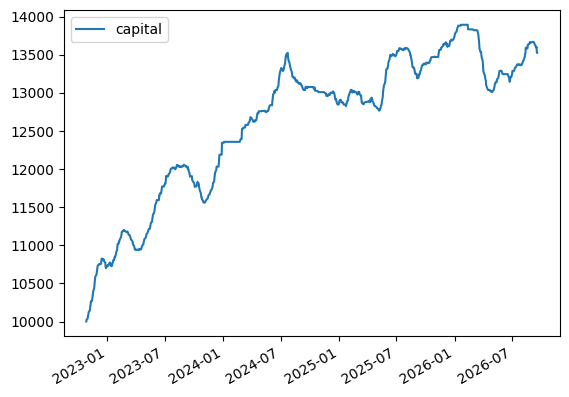

In [231]:
capital.rolling(30).sum().plot.line()
print(capital[-30:].sum())

### Debug optimal strategy with k=4 max trades per day

In [232]:
sim_params = SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=4, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)

res, capital_4trades = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=4, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1)
 Count bids 2502 in total, avg.bids per day 3.179161372299873,  filled bids 2004, fill bids percent = 0.8009592326139089
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 16, net profit = 593.5619535438966 
  Start capital = 10000, Resulting capital: 12961.457961283633 
  CAGR in 4 years: 1.067 or 6.7 % of avg. growth per year


In [233]:
filter_stop_loss = (res.lower_entry==1) & (res.stop_loss==1)
print(f'Average real close price if not stop_loss: {res[filter_stop_loss].growth_future_30d.mean()}')
res[filter_stop_loss].head(10)

Average real close price if not stop_loss: nan


,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return


In [234]:
filter_take_profit = (res.lower_entry==1) & (res.take_profit==1) & (res.stop_loss==0)
print(f'Average real close price if not take_profit: {res[filter_take_profit].growth_future_30d.mean()}')
res[filter_take_profit].head(10)

Average real close price if not take_profit: 1.3650340783144725


,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
64,407.306122,ASML,2022-10-10,0.649404,1.0,1.379595,1.446235,0.860769,0.933916,0.119404,0.261107,87.035816,1,0,1,117.498351,-0.174072,117.324279
68,385.747986,ASML,2022-10-11,0.632479,2.0,1.496660,1.527060,0.908875,0.994870,0.102479,0.247911,82.636860,1,0,1,111.559761,-0.165274,111.394487
69,11.544441,NVDA,2022-10-11,0.643700,1.0,1.384257,1.467115,0.933281,0.979199,0.113700,0.275058,91.685994,1,0,1,123.776093,-0.183372,123.592721
119,89.751831,META,2022-11-02,0.563660,2.0,1.282859,1.376960,0.972940,0.976475,0.033660,0.326438,112.322100,1,0,1,151.634836,-0.224644,151.410191
122,88.136032,META,2022-11-03,0.555167,4.0,1.343268,1.402204,0.990777,0.990777,0.025167,0.144314,52.312533,1,0,1,70.621920,-0.104625,70.517295
210,83.790001,AMZN,2022-12-22,0.580569,3.0,1.218642,1.360544,0.971834,0.989736,0.050569,0.260853,81.025240,1,0,1,109.384074,-0.162050,109.222023
221,83.040001,AMZN,2022-12-27,0.640978,1.0,1.183044,1.372832,0.980612,0.983743,0.110978,0.276757,85.588376,1,0,1,115.544308,-0.171177,115.373131
252,14.217465,NVDA,2023-01-05,0.573559,3.0,1.499334,1.615773,0.983807,0.983807,0.043559,0.210136,75.637164,1,0,1,102.110171,-0.151274,101.958897
889,291.066864,LICI.NS,2023-11-16,0.546112,1.0,1.409404,1.385032,0.991712,0.999097,0.016112,1.000000,440.622497,1,0,1,594.840371,-0.881245,593.959126
1533,152.530746,AVGO,2025-04-03,0.613103,3.0,1.484384,1.527693,0.896695,0.903643,0.083103,0.248433,73.505380,1,0,1,99.232263,-0.147011,99.085252


In [235]:
filter_no_stop_loss_no_take_profit = (res.lower_entry==1) & (res.take_profit==0) & (res.stop_loss==0)
print(f'Average real close price if no take_profit or stop loss: {res[filter_no_stop_loss_no_take_profit].growth_future_30d.mean()}')
res['realised_profit'] = res.future_net_return/res.investment
res[filter_no_stop_loss_no_take_profit][['growth_future_30d','realised_profit']].describe().T

Average real close price if no take_profit or stop loss: 1.0128057535969008


,count,mean,std,min,25%,50%,75%,max
growth_future_30d,1986.0,1.012806,0.086210,0.633172,0.957524,1.007125,1.063170,1.33784
realised_profit,1988.0,1.010793,0.086168,0.631172,0.955567,1.005120,1.061092,1.33584


capital    12961.457961
dtype: float64


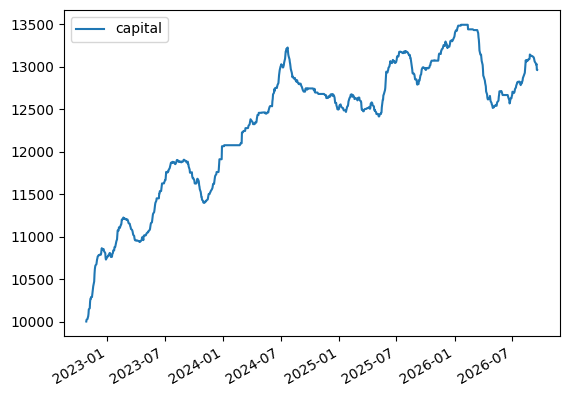

In [236]:
capital_4trades.rolling(30).sum().plot.line()
print(capital_4trades[-30:].sum())

### Debug optimal strategy with k=1 max trades per day

In [237]:
sim_params = SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=1, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)

res, capital_1_trade = simulate(new_df, sim_params)

SIMULATION STARTED
Simulations params: SimulationParams(initial_capital=10000, threshold=0.54, fees=0.002, top_k=1, portfolio_optimization=False, stop_loss=0.6, take_profit=1.35, lower_entry=1.0)
 Count bids 787 in total, avg.bids per day 1.0,  filled bids 626, fill bids percent = 0.795425667090216
  Stop loss events: count = 0, net loss = 0.0 
  Take profit events: count = 4, net profit = 466.7172829358433 
  Start capital = 10000, Resulting capital: 12958.483547697651 
  CAGR in 4 years: 1.067 or 6.69 % of avg. growth per year


In [238]:
# NO STOP LOSS events
filter_stop_loss = (res.lower_entry==1) & (res.stop_loss==1)
print(f'Average real close price if not stop_loss: {res[filter_stop_loss].growth_future_30d.mean()}')
res[filter_stop_loss].head(10)

Average real close price if not stop_loss: nan


,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return


In [239]:
filter_take_profit = (res.lower_entry==1) & (res.take_profit==1) & (res.stop_loss==0)
print(f'Average real close price if not take_profit: {res[filter_take_profit].growth_future_30d.mean()}')
res[filter_take_profit].head(5)

Average real close price if not take_profit: 1.3390750886093534


,Close_x,Ticker,Date,proba_pred10,pred10_rank,growth_future_30d,Ratio_MaxHighNext30_to_Close,Ratio_MinLowNext30_to_Close,Ratio_MinLowNext1_to_Close,weight,weight_norm,investment,lower_entry,stop_loss,take_profit,future_gross_return,fees,future_net_return
16,407.306122,ASML,2022-10-10,0.649404,1.0,1.379595,1.446235,0.860769,0.933916,0.119404,1.0,333.333333,1,0,1,450.000000,-0.666667,449.333333
17,11.544441,NVDA,2022-10-11,0.643700,1.0,1.384257,1.467115,0.933281,0.979199,0.113700,1.0,333.333333,1,0,1,450.000000,-0.666667,449.333333
66,83.040001,AMZN,2022-12-27,0.640978,1.0,1.183044,1.372832,0.980612,0.983743,0.110978,1.0,331.498773,1,0,1,447.523343,-0.662998,446.860346
279,291.066864,LICI.NS,2023-11-16,0.546112,1.0,1.409404,1.385032,0.991712,0.999097,0.016112,1.0,342.976178,1,0,1,463.017841,-0.685952,462.331888


In [240]:
filter_no_stop_loss_no_take_profit = (res.lower_entry==1) & (res.take_profit==0) & (res.stop_loss==0)
print(f'Average real close price if no take_profit or stop loss: {res[filter_no_stop_loss_no_take_profit].growth_future_30d.mean()}')
res['realised_profit'] = res.future_net_return/res.investment
res[filter_no_stop_loss_no_take_profit][['growth_future_30d','realised_profit']].describe().T

Average real close price if no take_profit or stop loss: 1.0126693081955653


,count,mean,std,min,25%,50%,75%,max
growth_future_30d,621.0,1.012669,0.083173,0.801663,0.956865,1.008759,1.063948,1.33784
realised_profit,622.0,1.010649,0.083108,0.799663,0.955046,1.006593,1.061948,1.33584


capital    12958.483548
dtype: float64


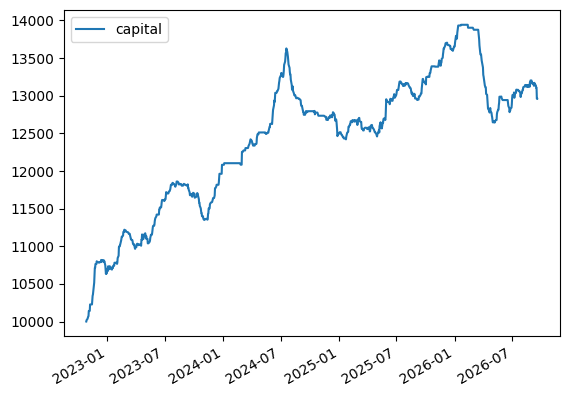

In [241]:
capital_1_trade.rolling(30).sum().plot.line()
print(capital_1_trade[-30:].sum())

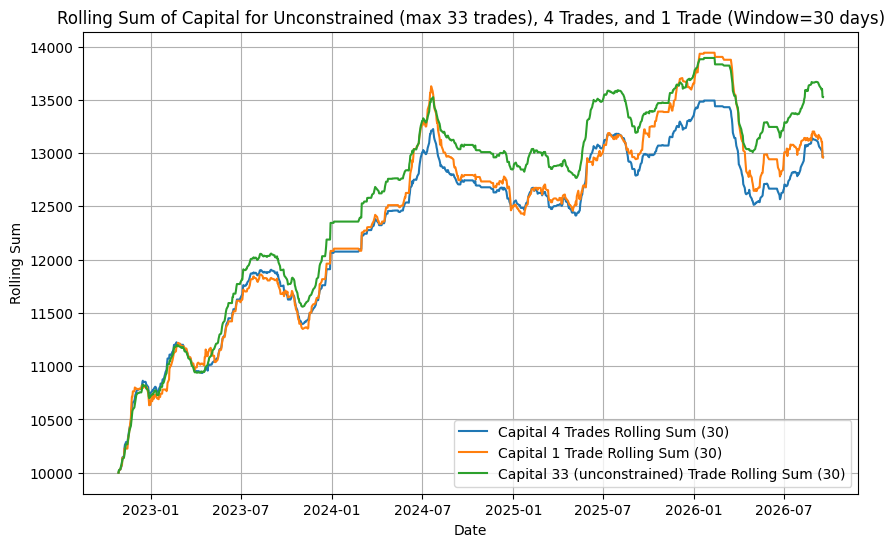

Capital 4 Trades Ending Sum: capital    12961.457961
dtype: float64
Capital 1 Trade Ending Sum: capital    12958.483548
dtype: float64
Capital Ending Sum: capital    13525.741761
dtype: float64


In [242]:
import matplotlib.pyplot as plt

# Assuming capital_6trades and capital_1_trade are defined and have the same index
capital_4trades_rolling = capital_4trades.rolling(30).sum()
capital_1_trade_rolling = capital_1_trade.rolling(30).sum()
capital_rolling = capital.rolling(30).sum()


# Plot the rolling sums on the same graph
plt.figure(figsize=(10, 6))
plt.plot(capital_4trades_rolling, label='Capital 4 Trades Rolling Sum (30)')
plt.plot(capital_1_trade_rolling, label='Capital 1 Trade Rolling Sum (30)')
plt.plot(capital_rolling, label='Capital 33 (unconstrained) Trade Rolling Sum (30)')

plt.legend(loc='best')
plt.title('Rolling Sum of Capital for Unconstrained (max 33 trades), 4 Trades, and 1 Trade (Window=30 days)')
plt.xlabel('Date')
plt.ylabel('Rolling Sum')
plt.grid(True)
plt.show()

# Print the ending values
print(f"Capital 4 Trades Ending Sum: {capital_4trades[-30:].sum()}")
print(f"Capital 1 Trade Ending Sum: {capital_1_trade[-30:].sum()}")
print(f"Capital Ending Sum: {capital[-30:].sum()}")